# Tarea 2 · Deep Learning (CIT3360) — YOLOv3-tiny escrita a mano, desde cero

> **Variante 80/10/10.** Copia de `../02b_yolo_a_mano.ipynb` que entrena y evalúa con la partición 80/10/10 de esta carpeta (train 2400, val 301 y test 301 imágenes; huella `84ea7ae5b688`). Solo cambian las rutas, la huella y los textos que dependen de la partición: el diseño, los hiperparámetros y las decisiones del grupo son los del original. Los pesos y registros van a `~/tarea2_runs_80_10_10/`.

Detector de una etapa con anclas, del tipo YOLOv3-tiny, entrenado **desde cero** (pesos aleatorios) sobre FjordFish. Sus capas, anclas, asignación, función de pérdida, decodificación y ciclo de entrenamiento están escritos en este cuaderno con PyTorch, sin Ultralytics, igual que la CNN propia (`01_cnn_propia_desde_cero.ipynb`). Usa las mismas particiones y el mismo evaluador que los demás modelos, y `05_comparacion.ipynb` lo compara con la YOLOv8n de Ultralytics (`02_yolo_desde_cero.ipynb`).

**Ítems de la rúbrica**
- 1.1 (modelos entrenados desde cero): secciones 3 a 14.
- 1.2 (mismas particiones): sección 2.
- 1.3 (justificación de las decisiones): sección 18.
- 1.4 (comparación): `05_comparacion.ipynb`, con los archivos que deja la sección 17.

**Decisiones del grupo que usa este cuaderno**

| | Decisión | Estado |
|---|---|---|
| D11 | Arquitectura y pérdida: YOLO clásica con anclas, tipo YOLOv3-tiny | decidida |
| D11 | Hiperparámetros: los de `02`, con calentamiento, acumulación, EMA y recorte de gradiente | decidida |
| D11 | Escala de la pérdida: 0,25 | decidida (prueba en la sección 11) |
| D3 | Entrada de 640 px con *letterbox* | decidida |
| D5 | El mismo aumento de datos de los demás modelos, sin mosaico | decidida |
| D6 | Las 28 categorías de `data.yaml` | decidida |
| D8 | Umbral común de confianza de 0,25 | decidida |

**Contenido**
0. Entorno · 1. Configuración · 2. Verificación de las particiones · 3. Datos · 4. Arquitectura · 5. Anclas · 6. Asignación y decodificación · 7. Función de pérdida · 8. Detecciones y NMS · 9. Optimizador y ciclo de entrenamiento · 10. Prueba de sobreajuste · 11. Prueba de la escala de la pérdida · 12. Entrenamiento · 13. Curvas · 14. Evaluación · 15. Eficiencia · 16. Resultados cualitativos · 17. Predicciones y resumen · 18–19. Justificación y análisis (grupo) · Declaración de uso de IA

### Diseño del detector frente a la YOLOv8n de `02`

Dos términos se usan en todo el cuaderno. Un **ancla** es una caja de referencia con ancho y alto fijos (sección 5). Una **candidata** es cada combinación de celda y ancla en la salida de la red: con 640 px hay 20² · 3 + 40² · 3 = 6000 por imagen, y para cada una la red predice 4 valores de caja, 1 de objeto y 28 de clase.

| Aspecto | YOLOv8n de Ultralytics (`02`) | Este cuaderno |
|---|---|---|
| Implementación | Librería Ultralytics | Escrita a mano en este cuaderno |
| Cuerpo | Bloques C2f y SPPF | 7 convoluciones 3×3 con BatchNorm y LeakyReLU, y *max-pool* |
| Escalas de salida | 3 (stride 8, 16 y 32) | 2 (stride 16 y 32) |
| Forma de predecir la caja | Sin anclas: distancias a los lados, con DFL | 3 anclas por celda, con desplazamiento del centro y ajuste de ancho y alto |
| Asignación | *Task-aligned*: varias positivas por caja real | Una positiva por caja real: el ancla de mayor IoU de forma, en la celda de su centro |
| Pérdida | CIoU + DFL + BCE de clase | Error cuadrático de caja + BCE de objeto + BCE de clase |
| Confianza | Probabilidad de clase | Probabilidad de objeto × probabilidad de clase |
| Hiperparámetros | SGD, tasa de 0,01 a 0,0001, momentum 0,937, weight decay 5e-4, lote 16, 300 épocas y paciencia 50 | Los mismos |
| Extras del entrenamiento | Calentamiento, acumulación hasta 64 imágenes, EMA y recorte de gradiente | Los mismos, escritos a mano |
| Datos y evaluación | Particiones, aumento y protocolo de detecciones comunes | Los mismos |

## 0. Entorno

Requiere PyTorch con CUDA, torchvision y OpenCV (ver `requirements.txt`) y `comun.py` en la misma carpeta. El detector, las anclas, la asignación, la pérdida y el entrenamiento están escritos en este cuaderno; no usa Ultralytics.

In [1]:
import copy
import json
import logging
import math
import os
import random
import time
import platform
import warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")   # cuBLAS determinista, como YOLO; debe ir antes de usar CUDA
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import torch
import torch.nn as nn
import torch.nn.functional as F
import yaml
from PIL import Image
from torchvision.ops import batched_nms, box_iou

logging.getLogger("torch.utils.flop_counter").setLevel(logging.ERROR)   # oculta un aviso sobre triton que aquí no aplica
from torch.utils.flop_counter import FlopCounterMode

from comun import (cargar_particiones, verificar_huella, leer_etiquetas_yolo, cargar_cajas_reales, evaluar_detecciones,
                   COLUMNAS_PREDICCIONES, CARPETA_RUNS)

warnings.filterwarnings("ignore", message=".*does not have a deterministic implementation.*")   # ver la sección 9

print("Python  :", platform.python_version())
print("PyTorch :", torch.__version__, "| CUDA disponible:", torch.cuda.is_available())
print("OpenCV  :", cv2.__version__)
if torch.cuda.is_available():
    print("GPU     :", torch.cuda.get_device_name(0))
DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cv2.setNumThreads(1)   # la carga en paralelo la hacen los hilos de `lotes`; así OpenCV no compite con ellos

Python  : 3.14.0
PyTorch : 2.14.0+cu130 | CUDA disponible: True
OpenCV  : 5.0.0
GPU     : NVIDIA GeForce RTX 4060 Laptop GPU


Estilo de los gráficos, con la misma paleta de los otros cuadernos.

In [2]:
# Estilo de los gráficos: colores categóricos en orden fijo (azul, naranja, aqua) y ejes discretos
AZUL, NARANJA, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#898781"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False, "figure.dpi": 100,
})

## 1. Configuración

Todos los parámetros están en esta celda; la arquitectura se define en la sección 4.

| Parámetro | Qué controla |
|---|---|
| `PRUEBA_RAPIDA`, `ENTRENAR`, `PROBAR_SOBREAJUSTE`, `PROBAR_ESCALA` | prueba rápida; entrenar o reutilizar el entrenamiento guardado; repetir las pruebas de las secciones 10 y 11 o mostrar las guardadas |
| `SEMILLA` | semilla de los números aleatorios |
| `LADO`, `NUM_CLASES`, `STRIDES`, `GRILLAS` | lado de la imagen de entrada (px), clases, reducción de cada escala de salida y celdas por lado de cada una |
| `ANCLAS_POR_ESCALA`, `SALIDAS_POR_ANCLA` | anclas por celda y valores que predice cada ancla: 4 de caja, 1 de objeto y 28 de clase |
| `PENDIENTE_LEAKY_RELU`, `BN_EPSILON`, `BN_MOMENTO` | activación y BatchNorm |
| `PROB_OBJETO_INICIAL`, `PROB_CLASE_INICIAL` | probabilidades con que parte cada candidata |
| `LIMITE_LOG_TAMANO` | recorte de `t_w` y `t_h` al decodificar |
| `REINICIOS_KMEANS` | veces que se repite el k-means de las anclas, para quedarse con el mejor resultado |
| `UMBRAL_IGNORAR` | IoU desde el que una candidata que no es positiva deja de contar como fondo |
| `PESO_CAJA`, `PESO_OBJETO`, `PESO_FONDO`, `PESO_CLASE` | pesos de cada término de la pérdida |
| `EPOCAS`, `PACIENCIA`, `LOTE` | máximo de épocas, parada temprana por mAP50-95 de validación e imágenes por lote (los de `02`) |
| `TASA_INICIAL`, `FRACCION_TASA_FINAL`, `MOMENTUM`, `WEIGHT_DECAY` | SGD con Nesterov y tasa con caída lineal (los de `02`) |
| `EPOCAS_CALENTAMIENTO`, `MOMENTUM_CALENTAMIENTO`, `TASA_SESGOS_CALENTAMIENTO` | calentamiento (los de Ultralytics) |
| `LOTE_NOMINAL` | imágenes por actualización de pesos |
| `GANANCIA_PERDIDA` | **D11:** factor que escala la pérdida, que el grupo eligió con la prueba de la sección 11 |
| `NORMA_MAXIMA_GRADIENTE`, `EMA_DECAIMIENTO`, `EMA_TAU` | recorte de gradiente y promedio móvil de los pesos (los de Ultralytics) |
| `PRECISION_MIXTA`, `USAR_AMP` | float16 para entrenar y para la validación de cada época; la evaluación final y la velocidad se miden en float32 |
| `HILOS_CARGA`, `LOTE_EVALUACION` | hilos que preparan las imágenes e imágenes por paso al evaluar (no cambian los resultados) |
| `ESCALA`, `TRASLACION`, `HSV_H`, `HSV_S`, `HSV_V`, `VOLTEO`, `COLOR_RELLENO` | aumento de datos y letterbox: los mismos de los demás modelos (D5) |
| `CONF_EVALUACION`, `IOU_NMS`, `MAX_DETECCIONES`, `MAX_ANTES_NMS` | detecciones que se guardan para el mAP: el protocolo común |
| `UMBRAL_CONFIANZA` | confianza mínima de las detecciones que se dibujan y de la precisión y el recall (D8) |
| `IMAGENES_SOBREAJUSTE`, `EPOCAS_SOBREAJUSTE` | tamaño de la prueba de sobreajuste |
| `ESCALAS_PROBADAS`, `EPOCAS_PRUEBA_ESCALA` | factores y épocas de la prueba de la escala de la pérdida |
| `N_IMAGENES_VELOCIDAD`, `N_EJEMPLOS` | imágenes para medir la velocidad y para los ejemplos cualitativos |
| `FRACCION_TRAIN` | parte de train que se usa (solo se reduce en la prueba rápida) |
| `DIR_DATASET`, `DIR_SPLITS`, `DIR_BASE`, `DIR_RUNS`, `DIR_RESULTADOS` | carpetas de entrada y salida |

Con `PRUEBA_RAPIDA = True` el cuaderno corre en unos minutos y escribe en `pruebas/`, sin pisar los resultados reales. Los pesos y registros del entrenamiento se guardan en `~/tarea2_runs_80_10_10/` (`CARPETA_RUNS` de `comun.py`), fuera de OneDrive; las tablas y figuras van en `resultados/yolo_a_mano/`.

In [3]:
RAIZ = Path.cwd()
PRUEBA_RAPIDA = False       # True: pocas imágenes y épocas para probar el flujo completo en minutos
ENTRENAR = False            # False: reutiliza el entrenamiento guardado en DIR_RUNS
PROBAR_SOBREAJUSTE = False  # en esta variante queda en False: se muestra la prueba guardada del cuaderno original
PROBAR_ESCALA = False       # en esta variante queda en False: se muestra la prueba guardada del cuaderno original

DIR_DATASET = RAIZ / "datasets" / "fjordfish"
DIR_SPLITS = RAIZ / "splits"
DIR_ORIGINAL = RAIZ.parent        # carpeta principal: la partición original y las pruebas de diseño guardadas
DIR_BASE = RAIZ / "pruebas" if PRUEBA_RAPIDA else RAIZ      # las pruebas no pisan los resultados reales
DIR_RUNS = CARPETA_RUNS / ("pruebas" if PRUEBA_RAPIDA else "reales") / "yolo_a_mano"   # pesos y registros, fuera de OneDrive
DIR_RESULTADOS = DIR_BASE / "resultados" / "yolo_a_mano"     # tablas y figuras para la presentación
SEMILLA = 42

# Detector: YOLOv3-tiny (D11)
LADO = 640                         # entrada de LADO × LADO px con letterbox (D3)
NUM_CLASES = 28                    # clases 0..27 de data.yaml (D6)
STRIDES = [32, 16]                 # reducción de cada escala de salida; el orden es el de las salidas de la red
GRILLAS = [LADO // s for s in STRIDES]   # 20 × 20 y 40 × 40 celdas
ANCLAS_POR_ESCALA = 3
SALIDAS_POR_ANCLA = 5 + NUM_CLASES       # 4 de caja + 1 de objeto + 28 de clase = 33
PENDIENTE_LEAKY_RELU = 0.1         # la de YOLOv3-tiny
BN_EPSILON, BN_MOMENTO = 1e-3, 0.03      # los que Ultralytics fija en su BatchNorm
PROB_OBJETO_INICIAL = 0.01         # el mismo valor de 01 (D2)
PROB_CLASE_INICIAL = 1 / NUM_CLASES      # las clases parten equiprobables
LIMITE_LOG_TAMANO = 8.0            # recorte de t_w y t_h al decodificar, para que exp() no se desborde
REINICIOS_KMEANS = 10

# Pérdida: la de YOLOv3, sin pesos adicionales
UMBRAL_IGNORAR = 0.5               # el de YOLOv3
PESO_CAJA, PESO_OBJETO, PESO_FONDO, PESO_CLASE = 1.0, 1.0, 1.0, 1.0

# Entrenamiento: los mismos valores de 02 (D11)
EPOCAS = 300
PACIENCIA = 50                     # épocas sin mejorar el mAP50-95 de validación
LOTE = 16
TASA_INICIAL = 0.01
FRACCION_TASA_FINAL = 0.01         # la tasa cae en forma lineal hasta TASA_INICIAL · FRACCION_TASA_FINAL
MOMENTUM = 0.937
WEIGHT_DECAY = 5e-4
EPOCAS_CALENTAMIENTO = 3.0

# Extras del entrenamiento: los mismos valores que Ultralytics usa en 02 (D11)
MOMENTUM_CALENTAMIENTO = 0.8
TASA_SESGOS_CALENTAMIENTO = 0.1
LOTE_NOMINAL = 64                  # imágenes por actualización de pesos: se acumulan 64 / LOTE = 4 lotes
NORMA_MAXIMA_GRADIENTE = 10.0
EMA_DECAIMIENTO, EMA_TAU = 0.9999, 2000
GANANCIA_PERDIDA = 0.25            # D11 (decidido por el grupo con la prueba de la sección 11)
PRECISION_MIXTA = True             # float16 en la GPU, como YOLO (AMP)
USAR_AMP = PRECISION_MIXTA and DISPOSITIVO.type == "cuda"
HILOS_CARGA = 8                    # hilos que leen y aumentan imágenes en paralelo
LOTE_EVALUACION = 16               # imágenes por paso al evaluar (no cambia los resultados)

# Aumento de datos y letterbox: los mismos valores de los demás modelos, sin mosaico (D5)
ESCALA = 0.5                       # factor de escala al azar en [1 − ESCALA, 1 + ESCALA]
TRASLACION = 0.1                   # desplazamiento al azar del centro: hasta ±10 % del lado
HSV_H, HSV_S, HSV_V = 0.015, 0.7, 0.4    # variación máxima de tono, saturación y brillo
VOLTEO = 0.5                       # probabilidad de volteo horizontal
COLOR_RELLENO = 114                # gris del letterbox (el mismo de Ultralytics)

# Evaluación: el protocolo común
CONF_EVALUACION = 0.001            # confianza mínima de las detecciones que se guardan para el mAP
IOU_NMS = 0.7
MAX_DETECCIONES = 300              # por imagen (el mismo límite que aplica comun.py)
MAX_ANTES_NMS = 30_000             # detecciones que entran al NMS por imagen (el mismo límite de Ultralytics)
UMBRAL_CONFIANZA = 0.25            # D8: umbral común que fijó el grupo con validación

# Prueba de sobreajuste, velocidad y ejemplos
IMAGENES_SOBREAJUSTE = 16
EPOCAS_SOBREAJUSTE = 1200          # una iteración por época: se actualizan los pesos cada 4 iteraciones
ESCALAS_PROBADAS = [1.0, 0.25, 0.0625]
EPOCAS_PRUEBA_ESCALA = 30
N_IMAGENES_VELOCIDAD = 200
N_EJEMPLOS = 4

FRACCION_TRAIN = 1.0               # parte de train que se usa (solo se reduce en la prueba rápida)
if PRUEBA_RAPIDA:
    EPOCAS = 2
    PACIENCIA = 2
    EPOCAS_SOBREAJUSTE = 8
    ESCALAS_PROBADAS = [1.0, 0.25]
    EPOCAS_PRUEBA_ESCALA = 1
    FRACCION_TRAIN = 0.05

random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
DIR_RUNS.mkdir(parents=True, exist_ok=True)
DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)
print(f"Grillas {GRILLAS} | {sum(g * g * ANCLAS_POR_ESCALA for g in GRILLAS)} candidatas por imagen "
      f"| {LOTE_NOMINAL // LOTE} lotes de {LOTE} por actualización de pesos")

Grillas [20, 40] | 6000 candidatas por imagen | 4 lotes de 16 por actualización de pesos


Funciones para dibujar que se usan en varias secciones: un lienzo de la red con sus cajas normalizadas, una imagen con cajas en píxeles (reales o predichas) y un eje de épocas con números enteros.

In [4]:
def dibujar_lienzo(ax, imagen, objetivos, titulo):
    """Muestra un lienzo de LADO × LADO con sus cajas (objetivos normalizados: clase, cx, cy, w, h)."""
    ax.imshow(imagen.permute(1, 2, 0).numpy())
    for _, cx, cy, w, h in objetivos.tolist():
        ax.add_patch(plt.Rectangle(((cx - w / 2) * LADO, (cy - h / 2) * LADO), w * LADO, h * LADO,
                                   fill=False, ec=NARANJA, lw=1.5))
    ax.set_title(titulo, fontsize=9)
    ax.axis("off")


def dibujar_cajas(ax, img, cajas, titulo):
    """Muestra una imagen con sus cajas en píxeles (tabla con clase_id, x1, y1, x2, y2 y, si la hay, confianza)."""
    ax.imshow(img)
    for fila in cajas.itertuples():
        ax.add_patch(plt.Rectangle((fila.x1, fila.y1), fila.x2 - fila.x1, fila.y2 - fila.y1,
                                   fill=False, ec=NARANJA, lw=1.5))
        texto = NOMBRES[fila.clase_id] + (f" {fila.confianza:.2f}" if hasattr(fila, "confianza") else "")
        ax.text(fila.x1, fila.y1, texto, color="white", fontsize=7, va="top" if fila.y1 < 0.05 * img.height else "bottom",
                bbox=dict(fc=NARANJA, ec="none", pad=1), clip_on=True)
    ax.set_title(titulo, fontsize=9)
    ax.axis("off")


def epocas_enteras(ax):
    """Deja solo números enteros en el eje de las épocas."""
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))

## 2. Verificación del dataset y de las particiones

Se comprueba que las carpetas del dataset coinciden con `splits/*.txt` y que la **huella** de las particiones es la común del grupo (`84ea7ae5b688`). Si no coincide, el cuaderno se detiene: así se garantiza que este modelo usa las mismas particiones que los demás (ítem 1.2).

In [5]:
assert (DIR_DATASET / "fjordfish.yaml").exists(), "Primero hay que ejecutar 00_preparacion_dataset.ipynb"
datos = yaml.safe_load((DIR_DATASET / "fjordfish.yaml").read_text(encoding="utf-8"))
NOMBRES = datos["names"]
assert len(NOMBRES) == NUM_CLASES, "NUM_CLASES no coincide con data.yaml"
particion, huella = cargar_particiones(DIR_SPLITS)
verificar_huella(huella)

filas = []
for s, ids in particion.items():
    en_disco = {p.stem for p in (DIR_DATASET / "images" / s).glob("*.jpg")}
    assert en_disco == set(ids), f"images/{s} no coincide con splits/{s}.txt"
    n_cajas = sum(len(leer_etiquetas_yolo(DIR_DATASET / "labels" / s / f"{i}.txt")) for i in ids)
    filas.append({"partición": s, "imágenes": len(ids), "cajas": n_cajas})
print(f"{NUM_CLASES} clases | huella de la partición: {huella} (verificada)")
pd.DataFrame(filas).set_index("partición")

28 clases | huella de la partición: 84ea7ae5b688 (verificada)


,imágenes,cajas
partición,,
train,2400,5076
val,301,622
test,301,649


## 3. Datos: letterbox y aumento de datos

Cada imagen se prepara igual que en YOLO (D3 y D5), en este orden:
1. Se cambia de tamaño para que su lado mayor mida `LADO` px, sin deformarla.
2. Se ubica en un lienzo gris de `LADO` × `LADO` (*letterbox*). En entrenamiento, además, se escala al azar entre 0,5× y 1,5× y su centro se desplaza hasta ±10 %; se descartan las cajas que quedan con menos del 10 % de su área o con un lado de 2 px o menos (el mismo criterio de Ultralytics).
3. Solo en entrenamiento: cambios de tono, saturación y brillo (HSV), que también afectan al relleno gris, y volteo horizontal con probabilidad 0,5.

Las cajas quedan como `clase, cx, cy, w, h`, normalizadas respecto del lienzo. En validación y test solo se aplica el letterbox centrado, y se guarda cómo deshacerlo para devolver las predicciones a píxeles de la imagen de `datasets/fjordfish/`.

Las imágenes se preparan en varios hilos en paralelo mientras la GPU procesa el lote anterior. Se usan hilos y no el `DataLoader` de PyTorch con procesos porque en Windows esos procesos no pueden usar clases definidas dentro de un cuaderno.

In [6]:
def cxcywh_a_xyxy(cajas):
    """Cajas (cx, cy, w, h) → (x1, y1, x2, y2), en las mismas unidades."""
    cx, cy, w, h = np.asarray(cajas, dtype=np.float64).reshape(-1, 4).T
    return np.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], axis=1)


def xyxy_a_cxcywh(cajas):
    """Cajas (x1, y1, x2, y2) → (cx, cy, w, h), en las mismas unidades."""
    x1, y1, x2, y2 = np.asarray(cajas, dtype=np.float64).reshape(-1, 4).T
    return np.stack([(x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1], axis=1)


def redimensionar(img):
    """Cambia el tamaño de la imagen para que su lado mayor mida LADO px, sin deformarla (como Ultralytics)."""
    alto, ancho = img.shape[:2]
    r = LADO / max(alto, ancho)
    tamano = (min(math.ceil(ancho * r), LADO), min(math.ceil(alto * r), LADO))
    return cv2.resize(img, tamano, interpolation=cv2.INTER_LINEAR)


def ubicar_en_lienzo(img, cajas, rng=None):
    """Letterbox: ubica la imagen en un lienzo gris de LADO × LADO; con `rng`, además la escala y la desplaza al azar."""
    # Devuelve el lienzo, las cajas que se conservan (px del lienzo), cuáles se conservan y (escala, dx, dy)
    alto, ancho = img.shape[:2]
    escala, centro_x, centro_y = 1.0, LADO / 2, LADO / 2
    if rng is not None:
        escala = rng.uniform(1 - ESCALA, 1 + ESCALA)
        centro_x, centro_y = rng.uniform(0.5 - TRASLACION, 0.5 + TRASLACION, size=2) * LADO
    dx, dy = centro_x - escala * ancho / 2, centro_y - escala * alto / 2   # la imagen queda centrada en (centro_x, centro_y)
    if rng is None:   # letterbox centrado con desplazamiento entero, como Ultralytics (sin interpolar medio píxel)
        dx, dy = round(dx - 0.1), round(dy - 0.1)
    matriz = np.array([[escala, 0, dx], [0, escala, dy]], dtype=np.float32)
    lienzo = cv2.warpAffine(img, matriz, (LADO, LADO), borderValue=(COLOR_RELLENO,) * 3)
    nuevas = (cajas * escala + [dx, dy, dx, dy]).clip(0, LADO)
    conservar = np.ones(len(cajas), dtype=bool)
    if rng is not None:   # mismo criterio que Ultralytics: lado > 2 px, al menos 10 % del área y proporción < 100
        ancho_antes, alto_antes = (cajas[:, 2] - cajas[:, 0]) * escala, (cajas[:, 3] - cajas[:, 1]) * escala
        ancho_ahora, alto_ahora = nuevas[:, 2] - nuevas[:, 0], nuevas[:, 3] - nuevas[:, 1]
        proporcion = np.maximum(ancho_ahora / (alto_ahora + 1e-16), alto_ahora / (ancho_ahora + 1e-16))
        conservar = ((ancho_ahora > 2) & (alto_ahora > 2) & (proporcion < 100)
                     & (ancho_ahora * alto_ahora / (ancho_antes * alto_antes + 1e-16) > 0.1))
    return lienzo, nuevas[conservar], conservar, (escala, dx, dy)


def variar_hsv(img, rng):
    """Cambia al azar el tono, la saturación y el brillo con las mismas tablas que Ultralytics (RandomHSV)."""
    r = rng.uniform(-1, 1, size=3) * [HSV_H, HSV_S, HSV_V]
    x = np.arange(256, dtype=np.float64)
    tono = ((x + r[0] * 180) % 180).astype(np.uint8)              # en OpenCV el tono va de 0 a 179
    saturacion = np.clip(x * (r[1] + 1), 0, 255).astype(np.uint8)
    brillo = np.clip(x * (r[2] + 1), 0, 255).astype(np.uint8)
    saturacion[0] = 0                                             # como Ultralytics: un gris o un blanco sigue sin color
    tabla = np.stack((tono, saturacion, brillo), axis=-1).reshape(1, 256, 3)
    return cv2.cvtColor(cv2.LUT(cv2.cvtColor(img, cv2.COLOR_BGR2HSV), tabla), cv2.COLOR_HSV2BGR)

El `Dataset` aplica esos pasos a cada imagen y entrega la imagen, sus cajas y los datos para deshacer el letterbox. La semilla del aumento depende de la imagen y de la época, así que cada época ve variantes nuevas y el resultado es reproducible.

In [7]:
class DatasetFjordFish(torch.utils.data.Dataset):
    """Imágenes y cajas de una partición, preparadas como en YOLO: letterbox y, si `aumentar`, aumento de datos."""

    def __init__(self, split, ids, aumentar):
        self.split, self.ids, self.aumentar = split, list(ids), aumentar
        self.epoca = 0                  # forma parte de la semilla del aumento: cada época ve variantes nuevas

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        """Devuelve la imagen (3 × LADO × LADO, uint8, RGB), sus objetivos (n, 5) y los datos para deshacer el letterbox."""
        id_img = self.ids[i]
        original = cv2.imread(str(DIR_DATASET / "images" / self.split / f"{id_img}.jpg"))     # BGR
        img = redimensionar(original)
        alto, ancho = img.shape[:2]
        etiquetas = leer_etiquetas_yolo(DIR_DATASET / "labels" / self.split / f"{id_img}.txt")
        cajas = cxcywh_a_xyxy(etiquetas[:, 1:]) * [ancho, alto, ancho, alto]
        rng = np.random.default_rng([SEMILLA, self.epoca, i]) if self.aumentar else None
        lienzo, cajas, conservar, (escala, dx, dy) = ubicar_en_lienzo(img, cajas, rng)
        clases = etiquetas[conservar, 0]
        if self.aumentar:
            lienzo = variar_hsv(lienzo, rng)
            if rng.random() < VOLTEO:
                lienzo = lienzo[:, ::-1]
                cajas[:, [0, 2]] = LADO - cajas[:, [2, 0]]          # al voltear, x1 nuevo = LADO − x2 y x2 nuevo = LADO − x1
        imagen = torch.from_numpy(np.ascontiguousarray(lienzo[..., ::-1].transpose(2, 0, 1)))   # BGR → RGB
        objetivos = torch.from_numpy(np.column_stack([clases, xyxy_a_cxcywh(cajas) / LADO]).astype(np.float32))
        # Para volver a px de la imagen original: x = (x_lienzo − dx) · factor_x  (y lo mismo en y)
        datos_letterbox = {"id": id_img, "ancho": original.shape[1], "alto": original.shape[0], "dx": dx, "dy": dy,
                           "factor_x": original.shape[1] / (ancho * escala), "factor_y": original.shape[0] / (alto * escala)}
        return imagen, objetivos, datos_letterbox

`lotes` recorre un dataset por lotes: las imágenes de cada lote se preparan en `HILOS_CARGA` hilos (OpenCV libera el GIL, así que trabajan en paralelo) y el lote siguiente se va preparando mientras la GPU procesa el actual.

In [8]:
def juntar(muestras):
    """Arma un lote: imágenes (B, 3, LADO, LADO), lista de objetivos por imagen y lista de datos del letterbox."""
    imagenes, objetivos, datos_letterbox = zip(*muestras)
    return torch.stack(imagenes), list(objetivos), list(datos_letterbox)


def lotes(dataset, tamano, mezclar=False):
    """Recorre el dataset en lotes de `tamano` imágenes, preparando el lote siguiente mientras se usa el actual."""
    indices = list(range(len(dataset)))
    if mezclar:
        random.shuffle(indices)
    grupos = [indices[i:i + tamano] for i in range(0, len(indices), tamano)]
    with ThreadPoolExecutor(HILOS_CARGA) as hilos, ThreadPoolExecutor(1) as anticipo:
        def preparar(grupo):
            return juntar(list(hilos.map(dataset.__getitem__, grupo)))

        siguiente = anticipo.submit(preparar, grupos[0]) if grupos else None
        for k in range(len(grupos)):
            lote = siguiente.result()
            if k + 1 < len(grupos):
                siguiente = anticipo.submit(preparar, grupos[k + 1])
            yield lote

Se crean los datasets de las tres particiones: solo train lleva aumento de datos. `FRACCION_TRAIN` reduce train únicamente en la prueba rápida.

In [9]:
ids_train = particion["train"]
if FRACCION_TRAIN < 1:                    # solo en la prueba rápida
    ids_train = sorted(random.Random(SEMILLA).sample(ids_train, max(1, round(len(ids_train) * FRACCION_TRAIN))))
datos_train = DatasetFjordFish("train", ids_train, aumentar=True)
datos_val = DatasetFjordFish("val", particion["val"], aumentar=False)
datos_test = DatasetFjordFish("test", particion["test"], aumentar=False)
rutas_test = sorted((DIR_DATASET / "images" / "test").glob("*.jpg"))   # para medir la velocidad y para los ejemplos
print(f"Imágenes · train: {len(datos_train)} | val: {len(datos_val)} | test: {len(datos_test)}")

Imágenes · train: 2400 | val: 301 | test: 301


Las mismas cuatro imágenes de train sin aumento (arriba, como se ven validación y test) y con aumento (abajo).

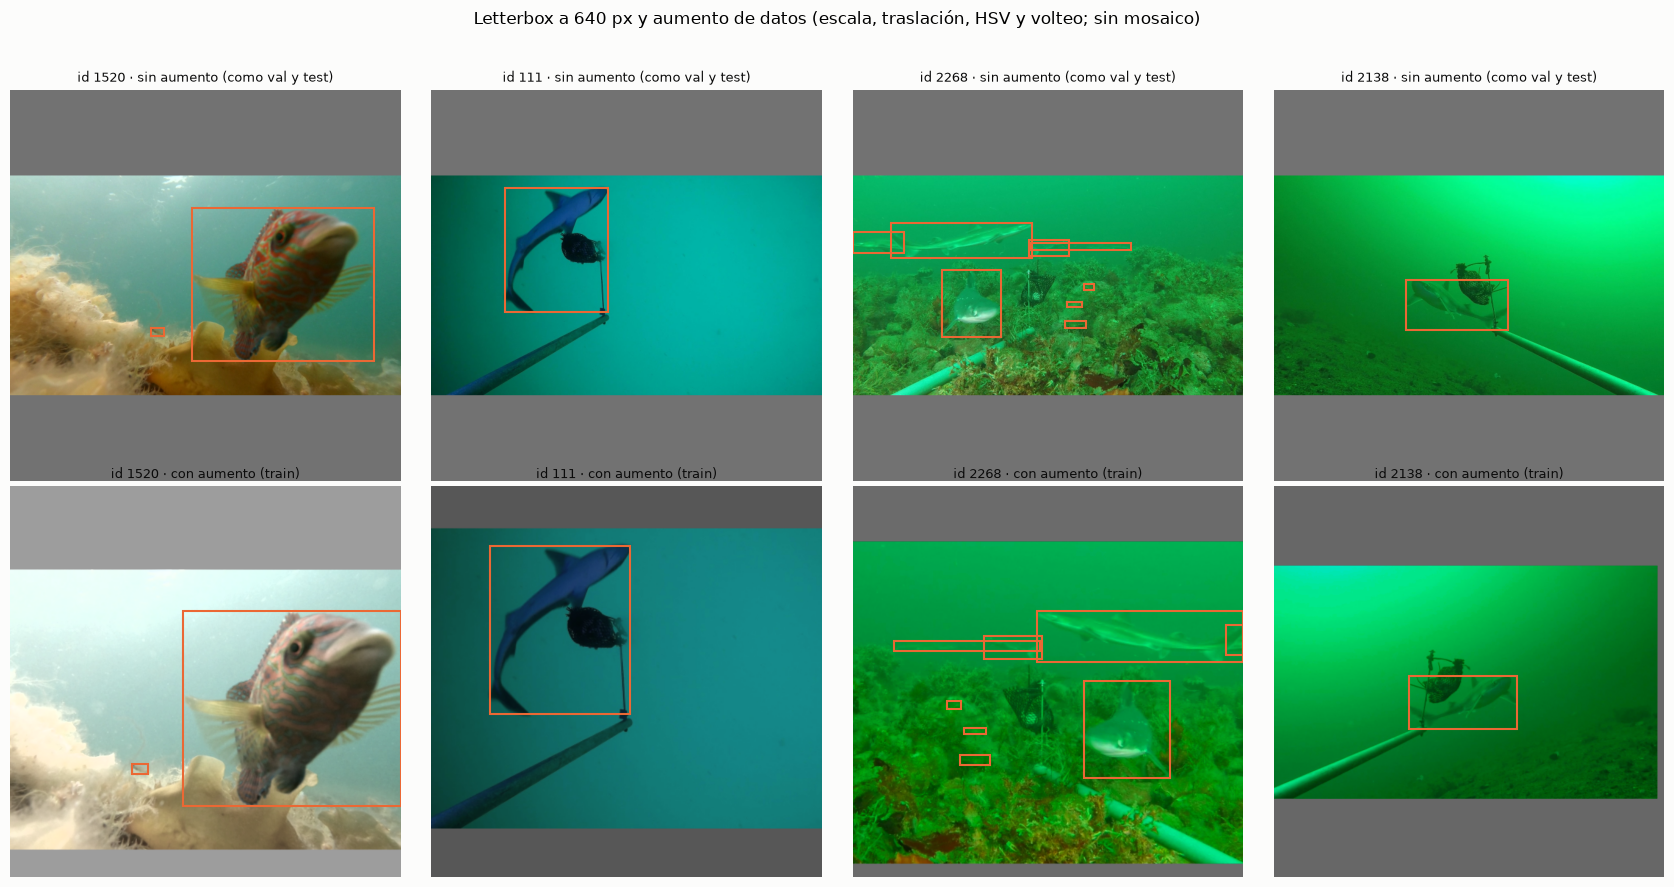

In [10]:
ids_ejemplo = random.Random(SEMILLA).sample(particion["train"], 4)
sin_aumento = DatasetFjordFish("train", ids_ejemplo, aumentar=False)
con_aumento = DatasetFjordFish("train", ids_ejemplo, aumentar=True)
fig, axes = plt.subplots(2, 4, figsize=(17, 9))
for k in range(4):
    imagen, objetivos, letterbox = sin_aumento[k]
    dibujar_lienzo(axes[0, k], imagen, objetivos, f"id {letterbox['id']} · sin aumento (como val y test)")
    imagen, objetivos, letterbox = con_aumento[k]
    dibujar_lienzo(axes[1, k], imagen, objetivos, f"id {letterbox['id']} · con aumento (train)")
fig.suptitle("Letterbox a 640 px y aumento de datos (escala, traslación, HSV y volteo; sin mosaico)", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(DIR_RESULTADOS / "aumento_de_datos.png", dpi=120, bbox_inches="tight")
plt.show()

## 4. Arquitectura

La red de YOLOv3-tiny (Redmon y Farhadi, 2018), descrita como listas de capas. Cada convolución lleva BatchNorm y LeakyReLU:
- **Hasta stride 16:** 5 convoluciones 3×3, de 16 a 256 filtros, con 4 *max-pool* de stride 2.
- **Hasta stride 32:** un *max-pool* de stride 2, convoluciones de 512 y 1024 filtros, entre ellas un *max-pool* de stride 1 que conserva el tamaño, y una convolución 1×1 de 256 filtros.
- **Cabeza de stride 32:** una convolución 3×3 de 512 filtros. Su salida es una grilla de 20 × 20.
- **Puente:** una convolución 1×1 de 128 filtros y una ampliación ×2. Se concatena con la salida del tramo "hasta stride 16".
- **Cabeza de stride 16:** una convolución 3×3 de 256 filtros. Su salida es una grilla de 40 × 40.
- **Salidas:** una convolución 1×1 en cada cabeza, con 3 anclas × 33 valores por celda.

Los pesos usan la inicialización por defecto de PyTorch, como YOLO de `02`. Los sesgos de las salidas hacen que cada candidata parta con probabilidad de objeto `PROB_OBJETO_INICIAL` y probabilidad de clase `PROB_CLASE_INICIAL`.

In [11]:
ARQUITECTURA = {
    "hasta_stride_16": [
        {"tipo": "conv", "filtros": 16}, {"tipo": "maxpool", "stride": 2},     # 640 → 320
        {"tipo": "conv", "filtros": 32}, {"tipo": "maxpool", "stride": 2},     # 320 → 160
        {"tipo": "conv", "filtros": 64}, {"tipo": "maxpool", "stride": 2},     # 160 → 80
        {"tipo": "conv", "filtros": 128}, {"tipo": "maxpool", "stride": 2},    # 80 → 40
        {"tipo": "conv", "filtros": 256},
    ],
    "hasta_stride_32": [
        {"tipo": "maxpool", "stride": 2},                                      # 40 → 20
        {"tipo": "conv", "filtros": 512}, {"tipo": "maxpool", "stride": 1},    # conserva 20 × 20
        {"tipo": "conv", "filtros": 1024},
        {"tipo": "conv", "filtros": 256, "tamano": 1},
    ],
    "cabeza_stride_32": [{"tipo": "conv", "filtros": 512}],
    "puente": [{"tipo": "conv", "filtros": 128, "tamano": 1}, {"tipo": "ampliar"}],   # 20 → 40
    "cabeza_stride_16": [{"tipo": "conv", "filtros": 256}],
}


def construir_tramo(entrada, capas):
    """Arma un tramo de la red desde una lista de capas; devuelve el módulo y sus canales de salida."""
    modulos = []
    for capa in capas:
        if capa["tipo"] == "conv":
            tamano = capa.get("tamano", 3)
            modulos += [nn.Conv2d(entrada, capa["filtros"], tamano, padding=tamano // 2, bias=False),   # BatchNorm ya tiene sesgo
                        nn.BatchNorm2d(capa["filtros"], eps=BN_EPSILON, momentum=BN_MOMENTO),
                        nn.LeakyReLU(PENDIENTE_LEAKY_RELU, inplace=True)]
            entrada = capa["filtros"]
        elif capa["tipo"] == "maxpool":
            if capa["stride"] == 1:                       # relleno a la derecha y abajo: el tamaño no cambia
                modulos.append(nn.ZeroPad2d((0, 1, 0, 1)))
            modulos.append(nn.MaxPool2d(kernel_size=2, stride=capa["stride"]))
        else:
            modulos.append(nn.Upsample(scale_factor=2, mode="nearest"))
    return nn.Sequential(*modulos), entrada


def logit(p):
    """Valor cuya sigmoide es p."""
    return math.log(p / (1 - p))


class YoloV3Tiny(nn.Module):
    """YOLOv3-tiny: dos escalas de salida, con ANCLAS_POR_ESCALA anclas por celda."""

    def __init__(self):
        super().__init__()
        self.hasta_16, canales_16 = construir_tramo(3, ARQUITECTURA["hasta_stride_16"])
        self.hasta_32, canales_32 = construir_tramo(canales_16, ARQUITECTURA["hasta_stride_32"])
        self.cabeza_32, canales_cabeza_32 = construir_tramo(canales_32, ARQUITECTURA["cabeza_stride_32"])
        self.puente, canales_puente = construir_tramo(canales_32, ARQUITECTURA["puente"])
        self.cabeza_16, canales_cabeza_16 = construir_tramo(canales_puente + canales_16, ARQUITECTURA["cabeza_stride_16"])
        self.salida_32 = nn.Conv2d(canales_cabeza_32, ANCLAS_POR_ESCALA * SALIDAS_POR_ANCLA, kernel_size=1)
        self.salida_16 = nn.Conv2d(canales_cabeza_16, ANCLAS_POR_ESCALA * SALIDAS_POR_ANCLA, kernel_size=1)
        for salida in (self.salida_32, self.salida_16):
            sesgo = salida.bias.data.view(ANCLAS_POR_ESCALA, SALIDAS_POR_ANCLA)
            sesgo[:, 4] = logit(PROB_OBJETO_INICIAL)
            sesgo[:, 5:] = logit(PROB_CLASE_INICIAL)

    @staticmethod
    def separar_anclas(y):
        """(B, ANCLAS · 33, S, S) → (B, ANCLAS, S, S, 33)."""
        b, _, s, _ = y.shape
        return y.reshape(b, ANCLAS_POR_ESCALA, SALIDAS_POR_ANCLA, s, s).permute(0, 1, 3, 4, 2)

    def forward(self, x):
        """Imágenes (B, 3, LADO, LADO) en [0, 1] → salida cruda de cada escala: [stride 32, stride 16]."""
        p16 = self.hasta_16(x)
        p32 = self.hasta_32(p16)
        y32 = self.salida_32(self.cabeza_32(p32))
        y16 = self.salida_16(self.cabeza_16(torch.cat([self.puente(p32), p16], dim=1)))
        return [self.separar_anclas(y32), self.separar_anclas(y16)]

La celda siguiente construye la red (todavía sin entrenar) y muestra cada capa con el tamaño de su salida y su número de parámetros.

In [12]:
modelo_inicial = YoloV3Tiny().to(DISPOSITIVO).eval()
filas, ganchos = [], []


def anotar_capa(capa, _, salida):
    """Agrega una fila con el tamaño de salida y los parámetros de una capa."""
    filas.append({"capa": type(capa).__name__, "salida (canales × alto × ancho)": " × ".join(map(str, salida.shape[1:])),
                  "parámetros": sum(p.numel() for p in capa.parameters())})


for capa in modelo_inicial.modules():
    if isinstance(capa, (nn.Conv2d, nn.BatchNorm2d, nn.MaxPool2d, nn.Upsample)):
        ganchos.append(capa.register_forward_hook(anotar_capa))
with torch.no_grad():
    modelo_inicial(torch.zeros(1, 3, LADO, LADO, device=DISPOSITIVO))
for gancho in ganchos:
    gancho.remove()
pd.DataFrame(filas)

,capa,salida (canales × alto × ancho),parámetros
0,Conv2d,16 × 640 × 640,432
1,BatchNorm2d,16 × 640 × 640,32
2,MaxPool2d,16 × 320 × 320,0
3,Conv2d,32 × 320 × 320,4608
4,BatchNorm2d,32 × 320 × 320,64
5,MaxPool2d,32 × 160 × 160,0
6,Conv2d,64 × 160 × 160,18432
7,BatchNorm2d,64 × 160 × 160,128
8,MaxPool2d,64 × 80 × 80,0
9,Conv2d,128 × 80 × 80,73728


Se verifica la forma de las salidas y se cuentan los parámetros y los GFLOPs de una pasada con una imagen de 640 × 640 (2 FLOPs por multiplicación-suma, la misma convención de los demás cuadernos).

In [13]:
def tamano_de_la_red(red):
    """Parámetros y GFLOPs de una pasada con una imagen de LADO × LADO."""
    red.eval()
    with torch.no_grad(), FlopCounterMode(display=False) as contador:
        red(torch.zeros(1, 3, LADO, LADO, device=DISPOSITIVO))
    return sum(p.numel() for p in red.parameters()), contador.get_total_flops() / 1e9


with torch.no_grad():
    salidas = modelo_inicial(torch.zeros(2, 3, LADO, LADO, device=DISPOSITIVO))
for salida, grilla in zip(salidas, GRILLAS):
    assert salida.shape == (2, ANCLAS_POR_ESCALA, grilla, grilla, SALIDAS_POR_ANCLA), f"forma inesperada: {salida.shape}"
n_parametros, gflops = tamano_de_la_red(modelo_inicial)
print(f"Salidas por imagen: {[tuple(s.shape[1:]) for s in salidas]} | parámetros: {n_parametros:,} | GFLOPs a {LADO} × {LADO}: {gflops:.1f}")

Salidas por imagen: [(3, 20, 20, 33), (3, 40, 40, 33)] | parámetros: 8,732,246 | GFLOPs a 640 × 640: 13.0


## 5. Anclas

Las 6 anclas se calculan como en YOLOv2 y YOLOv3: con k-means sobre el ancho y alto de las cajas de **train**, en píxeles del lienzo y sin aumento de datos, usando la distancia 1 − IoU. Se repite `REINICIOS_KMEANS` veces y se conserva el resultado con mayor IoU medio entre cada caja y su mejor ancla. Las 3 anclas más grandes van a la escala de stride 32 y las 3 más pequeñas a la de stride 16. Validación y test no se usan.

In [14]:
def iou_forma(a, b):
    """IoU entre cajas centradas en un mismo punto, según su ancho y alto: (n, 2) y (m, 2) → (n, m)."""
    interseccion = np.minimum(a[:, None, 0], b[None, :, 0]) * np.minimum(a[:, None, 1], b[None, :, 1])
    return interseccion / (a[:, None, 0] * a[:, None, 1] + b[None, :, 0] * b[None, :, 1] - interseccion + 1e-9)


def tamanos_en_lienzo(split, ids):
    """Ancho y alto en px del lienzo (letterbox sin aumento) de todas las cajas de una partición."""
    tamanos = []
    for id_img in ids:
        ancho, alto = Image.open(DIR_DATASET / "images" / split / f"{id_img}.jpg").size
        etiquetas = leer_etiquetas_yolo(DIR_DATASET / "labels" / split / f"{id_img}.txt")
        tamanos.append(etiquetas[:, 3:5] * [ancho, alto] * LADO / max(ancho, alto))
    return np.concatenate(tamanos)


def kmeans_anclas(tamanos, k, rng):
    """k-means con distancia 1 − IoU; cada centro se actualiza con la mediana de sus cajas."""
    centros = tamanos[rng.choice(len(tamanos), k, replace=False)]
    grupos = None
    for _ in range(1000):                 # termina antes, en cuanto ninguna caja cambia de grupo
        nuevos = iou_forma(tamanos, centros).argmax(axis=1)
        if grupos is not None and (nuevos == grupos).all():
            break
        grupos = nuevos
        centros = np.array([np.median(tamanos[grupos == i], axis=0) if (grupos == i).any() else centros[i] for i in range(k)])
    return centros


def calcular_anclas(tamanos, k):
    """Repite k-means y devuelve las anclas con mayor IoU medio, de menor a mayor área, y ese IoU."""
    rng = np.random.default_rng(SEMILLA)
    candidatas = [kmeans_anclas(tamanos, k, rng) for _ in range(REINICIOS_KMEANS)]
    medias = [iou_forma(tamanos, c).max(axis=1).mean() for c in candidatas]
    mejor = candidatas[int(np.argmax(medias))]
    return mejor[np.argsort(mejor.prod(axis=1))], max(medias)


tamanos_train = tamanos_en_lienzo("train", ids_train)
anclas_ordenadas, iou_medio_anclas = calcular_anclas(tamanos_train, len(STRIDES) * ANCLAS_POR_ESCALA)
ANCLAS_NP = anclas_ordenadas[::-1].reshape(len(STRIDES), ANCLAS_POR_ESCALA, 2).astype(np.float32)   # [stride 32, stride 16]
ANCLAS_NP = ANCLAS_NP[:, ::-1].copy()                                                               # en cada escala, de menor a mayor
ANCLAS = torch.from_numpy(ANCLAS_NP).to(DISPOSITIVO)
tabla_anclas = pd.DataFrame([{"stride": s, "ancla": a, "ancho (px)": w, "alto (px)": h}
                             for s, fila in zip(STRIDES, ANCLAS_NP) for a, (w, h) in enumerate(fila)])
tabla_anclas.to_csv(DIR_RESULTADOS / "anclas.csv", index=False)
print(f"Cajas de train: {len(tamanos_train)} | IoU medio entre cada caja y su mejor ancla: {iou_medio_anclas:.3f}")
tabla_anclas.round(1)

Cajas de train: 5076 | IoU medio entre cada caja y su mejor ancla: 0.617


,stride,ancla,ancho (px),alto (px)
0,32,0,76.699997,34.000000
1,32,1,114.500000,68.300003
2,32,2,242.300003,128.300003
3,16,0,20.000000,11.000000
4,16,1,43.299999,16.700001
5,16,2,31.200001,35.299999


Ancho y alto de cada caja de train, en escala logarítmica, con las anclas de cada escala de salida.

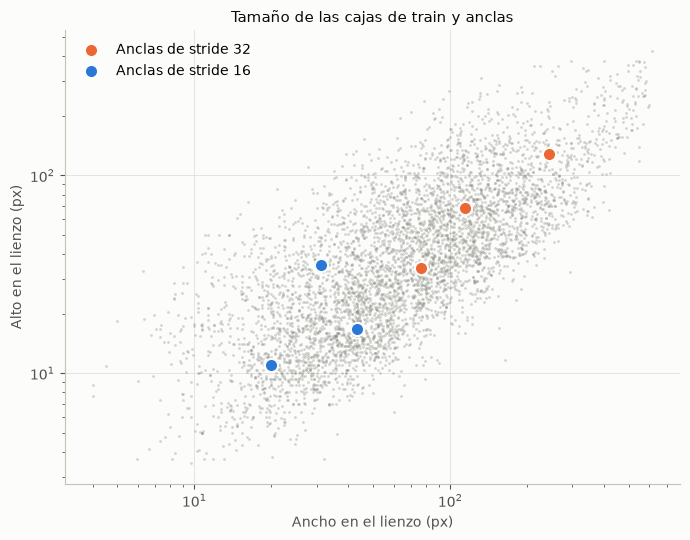

In [15]:
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(tamanos_train[:, 0], tamanos_train[:, 1], s=4, color=GRIS, alpha=0.35, linewidths=0)
for fila, stride, color in zip(ANCLAS_NP, STRIDES, (NARANJA, AZUL)):
    ax.scatter(fila[:, 0], fila[:, 1], s=90, color=color, edgecolors="#fcfcfb", linewidths=1.5, label=f"Anclas de stride {stride}")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Ancho en el lienzo (px)")
ax.set_ylabel("Alto en el lienzo (px)")
ax.set_title("Tamaño de las cajas de train y anclas")
ax.legend()
fig.tight_layout()
fig.savefig(DIR_RESULTADOS / "anclas.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Asignación y decodificación de las cajas

Como en YOLOv3, cada caja real tiene **una sola** candidata positiva:
1. Se busca, entre las 6 anclas, la de mayor IoU de forma con la caja. Esa ancla define la escala.
2. En esa escala, la candidata positiva es esa ancla en la celda que contiene el centro de la caja.
3. El objetivo de caja es el que recupera exactamente la caja real al decodificar: el desplazamiento del centro dentro de la celda y `t_w = ln(ancho / ancho del ancla)`, igual para el alto.

Si dos cajas caen en la misma celda y ancla, la última reemplaza a la anterior, como en YOLOv3. Esas cajas se cuentan y se informan como `cajas_sobrescritas`.

In [16]:
def asignar_objetivos(objetivos):
    """Por escala: positivas, objetivo de caja, peso del error de caja y clase; además, cuántas cajas se sobrescribieron."""
    tamano_lote = len(objetivos)
    asignacion = [{"positiva": torch.zeros(tamano_lote, ANCLAS_POR_ESCALA, g, g, dtype=torch.bool),
                   "caja": torch.zeros(tamano_lote, ANCLAS_POR_ESCALA, g, g, 4),
                   "peso": torch.zeros(tamano_lote, ANCLAS_POR_ESCALA, g, g),
                   "clase": torch.zeros(tamano_lote, ANCLAS_POR_ESCALA, g, g, dtype=torch.long)} for g in GRILLAS]
    sobrescritas = 0
    formas = ANCLAS_NP.reshape(-1, 2)
    for b, cajas in enumerate(objetivos):
        if not len(cajas):
            continue
        mejores = iou_forma(cajas[:, 3:5].numpy() * LADO, formas).argmax(axis=1)
        for (clase, cx, cy, w, h), mejor in zip(cajas.tolist(), mejores.tolist()):
            escala, ancla = mejor // ANCLAS_POR_ESCALA, mejor % ANCLAS_POR_ESCALA
            g = GRILLAS[escala]
            fila, columna = min(int(cy * g), g - 1), min(int(cx * g), g - 1)
            destino, lugar = asignacion[escala], (b, ancla, fila, columna)
            sobrescritas += int(destino["positiva"][lugar])
            ancho_ancla, alto_ancla = ANCLAS_NP[escala, ancla]
            destino["positiva"][lugar] = True
            destino["caja"][lugar] = torch.tensor([cx * g - columna, cy * g - fila,
                                                   math.log(max(w * LADO, 1e-3) / ancho_ancla),
                                                   math.log(max(h * LADO, 1e-3) / alto_ancla)])
            destino["peso"][lugar] = 2 - w * h      # YOLOv3: las cajas pequeñas pesan más
            destino["clase"][lugar] = int(clase)
    for destino in asignacion:
        for clave in destino:
            destino[clave] = destino[clave].to(DISPOSITIVO, non_blocking=True)
    return asignacion, sobrescritas

La **decodificación** hace el camino inverso: convierte los 4 valores de caja que predice cada candidata en una caja del lienzo. La pérdida también la usa:

`cx = (sigmoide(t_x) + columna) · stride`, `cy = (sigmoide(t_y) + fila) · stride`, `ancho = ancho del ancla · exp(t_w)`, `alto = alto del ancla · exp(t_h)`.

In [17]:
def decodificar(salida, escala):
    """Salida cruda de una escala → cajas (x1, y1, x2, y2) en px del lienzo: (B, ANCLAS, S, S, 4)."""
    g = salida.shape[2]
    fila, columna = torch.meshgrid(torch.arange(g, device=salida.device), torch.arange(g, device=salida.device), indexing="ij")
    cx = (torch.sigmoid(salida[..., 0]) + columna) * LADO / g
    cy = (torch.sigmoid(salida[..., 1]) + fila) * LADO / g
    anclas = ANCLAS[escala].view(1, ANCLAS_POR_ESCALA, 1, 1, 2)
    medio_ancho = anclas[..., 0] * torch.exp(salida[..., 2].clamp(-LIMITE_LOG_TAMANO, LIMITE_LOG_TAMANO)) / 2
    medio_alto = anclas[..., 1] * torch.exp(salida[..., 3].clamp(-LIMITE_LOG_TAMANO, LIMITE_LOG_TAMANO)) / 2
    return torch.stack([cx - medio_ancho, cy - medio_alto, cx + medio_ancho, cy + medio_alto], dim=-1)

## 7. Función de pérdida

Es la de YOLOv3, una suma por imagen sin pesos adicionales:

pérdida = caja + objeto + fondo + clase

- **Caja:** en cada candidata positiva, error cuadrático de `sigmoide(t_x)`, `sigmoide(t_y)`, `t_w` y `t_h` respecto de su objetivo, multiplicado por `2 − ancho · alto` (normalizados), para dar más peso a las cajas pequeñas.
- **Objeto:** entropía cruzada binaria (BCE) en las positivas, con objetivo 1.
- **Fondo:** BCE con objetivo 0 en las demás candidatas. Se **ignoran** las que no son positivas pero cuya caja predicha tiene IoU ≥ `UMBRAL_IGNORAR` con alguna caja real: ya cubren un objeto, así que no se castigan como fondo.
- **Clase:** BCE independiente por cada una de las 28 clases, solo en las positivas.

Los gradientes de cada lote se calculan con `GANANCIA_PERDIDA` · suma / `LOTE_NOMINAL`. Al acumular `LOTE_NOMINAL / LOTE` lotes, la actualización usa la pérdida media por imagen multiplicada por `GANANCIA_PERDIDA` (D11, sección 11). La pérdida se calcula siempre en float32, aunque la red corra en float16.

In [18]:
@torch.no_grad()
def candidatas_ignoradas(salidas, objetivos):
    """Por escala: candidatas cuya caja predicha tiene IoU ≥ UMBRAL_IGNORAR con alguna caja real de su imagen."""
    reales = torch.zeros(len(objetivos), max(max(len(o) for o in objetivos), 1), 4)   # rellenas con cajas vacías, de IoU 0
    for b, cajas in enumerate(objetivos):
        if len(cajas):
            reales[b, :len(cajas)] = torch.as_tensor(cxcywh_a_xyxy(cajas[:, 1:].numpy()) * LADO, dtype=torch.float32)
    reales = reales.to(DISPOSITIVO, non_blocking=True)[:, None]                       # (B, 1, cajas reales, 4)
    area_reales = (reales[..., 2] - reales[..., 0]) * (reales[..., 3] - reales[..., 1])
    ignoradas = []
    for escala, salida in enumerate(salidas):
        cajas = decodificar(salida, escala).reshape(len(salida), -1, 1, 4)            # (B, candidatas, 1, 4)
        ancho = (torch.minimum(cajas[..., 2], reales[..., 2]) - torch.maximum(cajas[..., 0], reales[..., 0])).clamp(min=0)
        alto = (torch.minimum(cajas[..., 3], reales[..., 3]) - torch.maximum(cajas[..., 1], reales[..., 1])).clamp(min=0)
        area_cajas = (cajas[..., 2] - cajas[..., 0]) * (cajas[..., 3] - cajas[..., 1])
        iou = ancho * alto / (area_cajas + area_reales - ancho * alto + 1e-9)
        ignoradas.append((iou.amax(dim=2) >= UMBRAL_IGNORAR).reshape(salida.shape[:4]))
    return ignoradas


def sumas_de_perdida(salidas, objetivos):
    """Sumas sin normalizar de un lote, por término de la pérdida, y cajas sobrescritas en la asignación."""
    asignacion, sobrescritas = asignar_objetivos(objetivos)
    ignoradas = candidatas_ignoradas(salidas, objetivos)
    caja = objeto = fondo = clase = salidas[0].new_zeros(())
    for salida, destino, ignorar in zip(salidas, asignacion, ignoradas):
        positiva = destino["positiva"]
        prediccion_caja = torch.cat([torch.sigmoid(salida[..., :2]), salida[..., 2:4]], dim=-1)
        error_caja = ((prediccion_caja - destino["caja"]) ** 2).sum(dim=-1) * destino["peso"]
        caja = caja + error_caja[positiva].sum()
        bce_objeto = F.binary_cross_entropy_with_logits(salida[..., 4], positiva.float(), reduction="none")
        objeto = objeto + bce_objeto[positiva].sum()
        fondo = fondo + bce_objeto[~positiva & ~ignorar].sum()
        if positiva.any():
            objetivo_clase = F.one_hot(destino["clase"][positiva], NUM_CLASES).float()
            clase = clase + F.binary_cross_entropy_with_logits(salida[..., 5:][positiva], objetivo_clase, reduction="sum")
    return {"caja": caja, "objeto": objeto, "fondo": fondo, "clase": clase, "sobrescritas": sobrescritas}


def perdida_total(sumas):
    """Suma ponderada de los términos de la pérdida."""
    return PESO_CAJA * sumas["caja"] + PESO_OBJETO * sumas["objeto"] + PESO_FONDO * sumas["fondo"] + PESO_CLASE * sumas["clase"]

Primero se define `inferir`, que pasa un lote por la red y se usa en todas las secciones siguientes. Después se calcula la pérdida de un lote con la red recién inicializada, y se verifican la forma de las imágenes y el rango de las clases.

In [19]:
def inferir(red, imagenes, precision_mixta=True):
    """Pasa un lote de imágenes uint8 por la red, normalizado a [0, 1]; en float16 si `precision_mixta`. Devuelve float32."""
    with torch.autocast(DISPOSITIVO.type, dtype=torch.float16, enabled=precision_mixta and USAR_AMP):
        salidas = red(imagenes.to(DISPOSITIVO, non_blocking=True).float() / 255)
    return [salida.float() for salida in salidas]


cargador = lotes(datos_train, LOTE)
imagenes, objetivos, _ = next(cargador)
cargador.close()                          # solo se necesita el primer lote
assert imagenes.shape == (LOTE, 3, LADO, LADO) and imagenes.dtype == torch.uint8, f"lote inesperado: {imagenes.shape}"
assert all(((o[:, 0] >= 0) & (o[:, 0] < NUM_CLASES)).all() for o in objetivos), "Hay clases fuera de 0..27"

with torch.no_grad():
    sumas = sumas_de_perdida(inferir(modelo_inicial, imagenes), objetivos)
print(f"Cajas reales en el lote: {sum(len(o) for o in objetivos)} | sobrescritas: {sumas['sobrescritas']}")
print("Pérdida inicial por imagen · " + " | ".join(f"{k}: {sumas[k].item() / LOTE:.3f}" for k in ("caja", "objeto", "fondo", "clase")))

Cajas reales en el lote: 56 | sobrescritas: 1
Pérdida inicial por imagen · caja: 3.448 | objeto: 15.826 | fondo: 60.331 | clase: 14.830


## 8. Detecciones y NMS

Para convertir la salida de la red en detecciones, con el protocolo común:
1. La confianza es la probabilidad de objeto multiplicada por la de clase. Cada candidata aporta una detección por cada clase que alcanza `CONF_EVALUACION` (NMS **multietiqueta**, como los demás modelos).
2. Se descartan las cajas vacías y, si quedan más de `MAX_ANTES_NMS`, se conservan las más confiables.
3. Se aplica NMS por clase (IoU `IOU_NMS`) y se dejan hasta `MAX_DETECCIONES` por imagen.
4. Se deshace el letterbox para llevar las cajas a píxeles de la imagen de `datasets/fjordfish/`.

Se usa la misma precisión numérica que YOLO: float16 en la validación de cada época del entrenamiento y float32 en la evaluación final.

In [20]:
def postprocesar(salidas, conf_minima=CONF_EVALUACION):
    """Salidas crudas de un lote → por imagen: (cajas x1, y1, x2, y2 en px del lienzo, confianzas, clases), tras NMS."""
    tamano_lote = len(salidas[0])
    cajas = torch.cat([decodificar(s, e).reshape(tamano_lote, -1, 4) for e, s in enumerate(salidas)], dim=1).clamp(0, LADO)
    confianzas = torch.cat([(torch.sigmoid(s[..., 4:5]) * torch.sigmoid(s[..., 5:])).reshape(tamano_lote, -1, NUM_CLASES)
                            for s in salidas], dim=1)
    detecciones = []
    for b in range(tamano_lote):
        xyxy = cajas[b]
        no_vacia = (xyxy[:, 2] > xyxy[:, 0]) & (xyxy[:, 3] > xyxy[:, 1])
        # una detección por cada par (candidata, clase) que alcanza la confianza mínima (NMS multietiqueta)
        candidata, clase = torch.nonzero((confianzas[b] >= conf_minima) & no_vacia[:, None], as_tuple=True)
        conf = confianzas[b][candidata, clase]
        if len(conf) > MAX_ANTES_NMS:
            mejores = conf.topk(MAX_ANTES_NMS).indices
            candidata, clase, conf = candidata[mejores], clase[mejores], conf[mejores]
        quedan = batched_nms(xyxy[candidata], conf, clase, IOU_NMS)[:MAX_DETECCIONES]
        detecciones.append((xyxy[candidata[quedan]], conf[quedan], clase[quedan]))
    return detecciones


def a_filas(detecciones, lista_letterbox):
    """Detecciones en px del lienzo → filas del formato común, en px de la imagen de datasets/fjordfish."""
    filas = []
    for (xyxy, conf, cls), letterbox in zip(detecciones, lista_letterbox):
        xyxy = xyxy.cpu().numpy()
        x = ((xyxy[:, [0, 2]] - letterbox["dx"]) * letterbox["factor_x"]).clip(0, letterbox["ancho"])   # se deshace el letterbox
        y = ((xyxy[:, [1, 3]] - letterbox["dy"]) * letterbox["factor_y"]).clip(0, letterbox["alto"])
        for c, p, (x1, x2), (y1, y2) in zip(cls.tolist(), conf.tolist(), x.tolist(), y.tolist()):
            filas.append((letterbox["id"], c, round(p, 5), round(x1, 1), round(y1, 1), round(x2, 1), round(y2, 1)))
    return filas


@torch.no_grad()
def predecir(red, dataset, precision_mixta=False):
    """Detecciones de la red en un dataset sin aumento, en el formato común (por defecto en float32, como YOLO al evaluar)."""
    red.eval()
    filas = []
    for imagenes, _, lista_letterbox in lotes(dataset, LOTE_EVALUACION):
        filas += a_filas(postprocesar(inferir(red, imagenes, precision_mixta)), lista_letterbox)
    return pd.DataFrame(filas, columns=COLUMNAS_PREDICCIONES)

**Comprobación de ida y vuelta.** Antes de entrenar se comprueba que la asignación, la pérdida y la decodificación son coherentes entre sí. A partir de las cajas reales de un lote de validación se arma la salida que daría una red perfecta. Esa salida debe recuperar cada caja real, con su clase, y dar una pérdida cercana a 0.

In [21]:
def salida_perfecta(objetivos):
    """Arma la salida cruda que corresponde exactamente a las cajas reales de un lote."""
    asignacion, sobrescritas = asignar_objetivos(objetivos)
    salidas = []
    for destino in asignacion:
        positiva = destino["positiva"]
        centro = destino["caja"][..., :2].clamp(1e-6, 1 - 1e-6)
        salida = torch.full((*positiva.shape, SALIDAS_POR_ANCLA), -30.0, device=DISPOSITIVO)
        salida[..., :2] = torch.log(centro / (1 - centro))
        salida[..., 2:4] = destino["caja"][..., 2:4]
        salida[..., 4][positiva] = 30.0
        salida[..., 5:][positiva] = 30.0 * (2 * F.one_hot(destino["clase"][positiva], NUM_CLASES).float() - 1)
        salidas.append(salida)
    return salidas, sobrescritas


cargador = lotes(datos_val, LOTE_EVALUACION)
_, objetivos, lista_letterbox = next(cargador)
cargador.close()
salidas_ideales, sobrescritas_ideales = salida_perfecta(objetivos)
sumas_ideales = sumas_de_perdida(salidas_ideales, objetivos)
n_cajas = sum(len(o) for o in objetivos)
n_recuperadas = 0
for (xyxy, _, clases), reales in zip(postprocesar(salidas_ideales, conf_minima=0.5), objetivos):
    if len(reales):
        reales_xyxy = torch.as_tensor(cxcywh_a_xyxy(reales[:, 1:].numpy()) * LADO, dtype=torch.float32, device=DISPOSITIVO)
        iou_con_reales = box_iou(reales_xyxy, xyxy) if len(xyxy) else torch.zeros(len(reales), 1, device=DISPOSITIVO)
        misma_clase = reales[:, 0].to(DISPOSITIVO)[:, None] == clases[None, :] if len(xyxy) else torch.zeros_like(iou_con_reales, dtype=torch.bool)
        n_recuperadas += ((iou_con_reales * misma_clase).amax(dim=1) > 0.99).sum().item()
print(f"Cajas recuperadas: {n_recuperadas} de {n_cajas} ({sobrescritas_ideales} sobrescritas) | "
      f"pérdida de la salida perfecta: {perdida_total(sumas_ideales).item():.2e}")
assert n_recuperadas >= n_cajas - sobrescritas_ideales, "La decodificación no recupera las cajas reales"
assert perdida_total(sumas_ideales).item() < 1e-3, "La pérdida de una salida perfecta debería ser casi 0"
del modelo_inicial, salidas, salidas_ideales      # no deben contar en la memoria de la GPU del entrenamiento
torch.cuda.empty_cache()

Cajas recuperadas: 40 de 40 (0 sobrescritas) | pérdida de la salida perfecta: 7.56e-12


## 9. Optimizador y ciclo de entrenamiento

Reproduce, escrito a mano, lo que hace Ultralytics en `02` (D11):
- **SGD con momentum de Nesterov**, con tres grupos de parámetros: pesos con `WEIGHT_DECAY` (convoluciones), pesos de BatchNorm sin decaimiento, y sesgos sin decaimiento.
- **Tasa de aprendizaje** con caída lineal por época, de `TASA_INICIAL` a `TASA_INICIAL · FRACCION_TASA_FINAL`, calculada para `EPOCAS` épocas.
- **Calentamiento** durante las primeras `EPOCAS_CALENTAMIENTO` épocas: la tasa de los sesgos baja desde `TASA_SESGOS_CALENTAMIENTO`, la de los demás sube desde 0, el momentum sube desde `MOMENTUM_CALENTAMIENTO` y los lotes acumulados suben de 1 a `LOTE_NOMINAL / LOTE`.
- **Acumulación:** los pesos se actualizan cada `LOTE_NOMINAL / LOTE` lotes.
- **Recorte de gradiente** a la norma `NORMA_MAXIMA_GRADIENTE`, antes de actualizar.
- **EMA:** un promedio móvil exponencial de los pesos, y de las estadísticas de BatchNorm, se actualiza después de cada paso. La validación y el mejor modelo usan estos pesos promediados.
- **Precisión mixta:** el `GradScaler` escala la pérdida para que los gradientes en float16 no se vuelvan cero.

In [22]:
def factor_tasa(epoca, epocas):
    """Caída lineal de la tasa: 1 en la primera época y FRACCION_TASA_FINAL al final (`epoca` parte en 0)."""
    return max(1 - epoca / epocas, 0) * (1 - FRACCION_TASA_FINAL) + FRACCION_TASA_FINAL


def crear_optimizador(red):
    """SGD con Nesterov y tres grupos: sesgos, pesos de convolución (con decaimiento) y pesos de BatchNorm."""
    sesgos, pesos, normalizacion = [], [], []
    for modulo in red.modules():
        for nombre, parametro in modulo.named_parameters(recurse=False):
            if nombre == "bias":
                sesgos.append(parametro)
            elif isinstance(modulo, nn.BatchNorm2d):
                normalizacion.append(parametro)
            else:
                pesos.append(parametro)
    comunes = {"lr": TASA_INICIAL, "initial_lr": TASA_INICIAL, "momentum": MOMENTUM, "nesterov": True}
    return torch.optim.SGD([{"params": sesgos, "weight_decay": 0.0, "grupo": "sesgos", **comunes},
                            {"params": pesos, "weight_decay": WEIGHT_DECAY, "grupo": "pesos", **comunes},
                            {"params": normalizacion, "weight_decay": 0.0, "grupo": "normalizacion", **comunes}])


class PesosEMA:
    """Promedio móvil exponencial de los pesos y de las estadísticas de BatchNorm."""

    def __init__(self, red):
        self.red = copy.deepcopy(red).eval().requires_grad_(False)
        self.actualizaciones = 0

    @torch.no_grad()
    def actualizar(self, red):
        """Acerca cada valor al de la red; el decaimiento parte bajo y sube hasta EMA_DECAIMIENTO."""
        self.actualizaciones += 1
        decaimiento = EMA_DECAIMIENTO * (1 - math.exp(-self.actualizaciones / EMA_TAU))
        actuales = red.state_dict()
        for nombre, valor in self.red.state_dict().items():
            if valor.dtype.is_floating_point:
                valor.mul_(decaimiento).add_(actuales[nombre].detach(), alpha=1 - decaimiento)


class Entrenamiento:
    """Lo que cambia durante el entrenamiento: optimizador, escalador, EMA, iteración y lotes acumulados."""

    def __init__(self, red, lotes_por_epoca, epocas, ganancia=None):
        self.red, self.epocas = red, epocas
        self.ganancia = GANANCIA_PERDIDA if ganancia is None else ganancia
        self.optimizador = crear_optimizador(red)
        self.escalador = torch.amp.GradScaler("cuda", enabled=USAR_AMP)
        self.ema = PesosEMA(red)
        self.iteracion, self.ultimo_paso = 0, -1     # iteración actual y la de la última actualización de pesos
        self.acumular_final = max(round(LOTE_NOMINAL / LOTE), 1)
        self.acumular = self.acumular_final
        self.fin_calentamiento = round(EPOCAS_CALENTAMIENTO * lotes_por_epoca)

    def fijar_tasa_de_epoca(self, epoca):
        """Aplica la caída lineal de la tasa al comenzar una época."""
        for grupo in self.optimizador.param_groups:
            grupo["lr"] = grupo["initial_lr"] * factor_tasa(epoca, self.epocas)

    def calentar(self, epoca):
        """Durante el calentamiento, ajusta tasa, momentum y lotes acumulados según la iteración."""
        if self.iteracion > self.fin_calentamiento:
            return
        tramo = [0, self.fin_calentamiento]
        self.acumular = max(1, int(np.interp(self.iteracion, tramo, [1, self.acumular_final]).round()))
        for grupo in self.optimizador.param_groups:
            inicio = TASA_SESGOS_CALENTAMIENTO if grupo["grupo"] == "sesgos" else 0.0
            grupo["lr"] = float(np.interp(self.iteracion, tramo, [inicio, grupo["initial_lr"] * factor_tasa(epoca, self.epocas)]))
            grupo["momentum"] = float(np.interp(self.iteracion, tramo, [MOMENTUM_CALENTAMIENTO, MOMENTUM]))

    def actualizar_pesos(self):
        """Recorta el gradiente, actualiza los pesos y la EMA; devuelve la norma del gradiente y si el paso se descartó."""
        self.escalador.unscale_(self.optimizador)
        norma = nn.utils.clip_grad_norm_(self.red.parameters(), NORMA_MAXIMA_GRADIENTE)
        escala_antes = self.escalador.get_scale()
        self.escalador.step(self.optimizador)
        self.escalador.update()
        self.optimizador.zero_grad(set_to_none=True)
        self.ema.actualizar(self.red)
        return float(norma), self.escalador.get_scale() < escala_antes   # GradScaler baja la escala si descarta un paso

Estas funciones se usan en las pruebas de las secciones 10 y 11 y en el entrenamiento completo:
- **`entrenar_epoca`** recorre train y actualiza los pesos cada vez que se acumulan los lotes necesarios. Si al final de una época quedan lotes sin usar, pasan a la siguiente, como en Ultralytics.
- **`validar`** evalúa en una sola pasada: con la misma salida de la red calcula la pérdida, las detecciones y sus métricas.
- **`modo_determinista`** activa los algoritmos reproducibles de PyTorch, igual que YOLO con `deterministic=True`.

Las pérdidas que se informan son por imagen. La **norma del gradiente** se registra para saber con qué frecuencia actúa el recorte.

In [23]:
CLAVES_PERDIDA = ("caja", "objeto", "fondo", "clase")


def promedios(sumas, n_imagenes):
    """Pérdida total y por término, por imagen."""
    terminos = {f"perdida_{k}": sumas[k] / max(n_imagenes, 1) for k in CLAVES_PERDIDA}
    return {"perdida": float(perdida_total(sumas) / max(n_imagenes, 1)), **terminos}


def modo_determinista(activar):
    """Activa o desactiva los algoritmos deterministas de PyTorch, igual que YOLO con deterministic=True."""
    torch.use_deterministic_algorithms(activar, warn_only=True)
    torch.backends.cudnn.deterministic = activar
    torch.utils.deterministic.fill_uninitialized_memory = not activar   # Ultralytics también omite este relleno


def entrenar_epoca(estado, dataset, epoca):
    """Una época (`epoca` parte en 0); al final avanza `dataset.epoca`, así la siguiente ve otro aumento."""
    estado.red.train()
    estado.fijar_tasa_de_epoca(epoca)
    sumas = dict.fromkeys(CLAVES_PERDIDA, 0.0)
    sobrescritas, descartados, normas = 0, 0, []
    for imagenes, objetivos, _ in lotes(dataset, LOTE, mezclar=True):
        estado.calentar(epoca)
        terminos = sumas_de_perdida(inferir(estado.red, imagenes), objetivos)
        estado.escalador.scale(estado.ganancia * perdida_total(terminos) / LOTE_NOMINAL).backward()
        for k in CLAVES_PERDIDA:
            sumas[k] += terminos[k].item()
        sobrescritas += terminos["sobrescritas"]
        if estado.iteracion - estado.ultimo_paso >= estado.acumular:
            norma, descartado = estado.actualizar_pesos()
            normas.append(norma)
            descartados += descartado
            estado.ultimo_paso = estado.iteracion
        estado.iteracion += 1
    dataset.epoca += 1
    normas = [n for n in normas if math.isfinite(n)]   # los pasos con gradiente infinito los descarta el GradScaler
    return {**promedios(sumas, len(dataset)), "sobrescritas": sobrescritas, "pasos_descartados": descartados,
            "norma_gradiente": float(np.mean(normas)) if normas else 0.0,
            "fraccion_recortada": float(np.mean(np.array(normas) > NORMA_MAXIMA_GRADIENTE)) if normas else 0.0}


@torch.no_grad()
def validar(red, dataset, reales):
    """Una pasada por un dataset sin aumento: pérdida, métricas del evaluador común y detecciones."""
    red.eval()
    sumas = dict.fromkeys(CLAVES_PERDIDA, 0.0)
    filas = []
    for imagenes, objetivos, lista_letterbox in lotes(dataset, LOTE_EVALUACION):
        salidas = inferir(red, imagenes)               # float16, como la validación de YOLO durante el entrenamiento
        terminos = sumas_de_perdida(salidas, objetivos)
        for k in CLAVES_PERDIDA:
            sumas[k] += terminos[k].item()
        filas += a_filas(postprocesar(salidas), lista_letterbox)
    detecciones = pd.DataFrame(filas, columns=COLUMNAS_PREDICCIONES)
    return promedios(sumas, len(dataset)), evaluar_detecciones(detecciones, reales), detecciones

## 10. Prueba de sobreajuste

Antes del entrenamiento largo se comprueba si la red **puede aprenderse `IMAGENES_SOBREAJUSTE` (16) imágenes de train sin aumento**, las mismas de la prueba de `01`. Si no logra memorizarlas, el problema está en la asignación, la pérdida o la decodificación, y no en los hiperparámetros. Aprende si su mAP50 sobre esas mismas imágenes se acerca a 1.

> **En esta variante** la prueba no se repite: se muestra la guardada del cuaderno original (`../02b_yolo_a_mano.ipynb`), hecha con 16 imágenes de la partición original. `PROBAR_SOBREAJUSTE` debe quedar en `False`.

In [24]:
# Esta variante no repite la prueba: muestra la guardada del cuaderno original, hecha con 16 imágenes de su train
assert not PROBAR_SOBREAJUSTE, "En esta variante la prueba no se repite: se muestra la del cuaderno original"
DIR_DATASET_ORIGINAL = DIR_ORIGINAL / "datasets" / "fjordfish"
DIR_PRUEBA_GUARDADA = DIR_ORIGINAL / "resultados" / "yolo_a_mano"
ids_train_original = (DIR_ORIGINAL / "splits" / "train.txt").read_text().split()
ids_sobreajuste = sorted(random.Random(SEMILLA).sample(ids_train_original, IMAGENES_SOBREAJUSTE))
datos_sobreajuste = DatasetFjordFish("train", ids_sobreajuste, aumentar=False)
reales_sobreajuste = cargar_cajas_reales(DIR_DATASET_ORIGINAL, "train", ids_sobreajuste)
ARCHIVO_SOBREAJUSTE = DIR_PRUEBA_GUARDADA / "prueba_sobreajuste.csv"
ARCHIVO_SOBREAJUSTE_CURVA = DIR_PRUEBA_GUARDADA / "prueba_sobreajuste_curva.csv"
ARCHIVO_SOBREAJUSTE_PRED = DIR_PRUEBA_GUARDADA / "prueba_sobreajuste_predicciones.csv"

if PROBAR_SOBREAJUSTE:
    modo_determinista(True)
    random.seed(SEMILLA)
    torch.manual_seed(SEMILLA)
    red_sobreajuste = YoloV3Tiny().to(DISPOSITIVO)
    estado_sobreajuste = Entrenamiento(red_sobreajuste, 1, EPOCAS_SOBREAJUSTE)
    t_inicio = time.perf_counter()
    curva_sobreajuste = [entrenar_epoca(estado_sobreajuste, datos_sobreajuste, e) for e in range(EPOCAS_SOBREAJUSTE)]
    perdidas_sobreajuste, metricas_sobreajuste, pred_sobreajuste = validar(estado_sobreajuste.ema.red, datos_sobreajuste, reales_sobreajuste)
    modo_determinista(False)
    tabla_sobreajuste = pd.Series({
        "pérdida en la iteración 1": curva_sobreajuste[0]["perdida"], "pérdida final (entrenamiento)": curva_sobreajuste[-1]["perdida"],
        "pérdida final (modo evaluación)": perdidas_sobreajuste["perdida"], "mAP50": metricas_sobreajuste["mAP50"],
        "mAP50-95": metricas_sobreajuste["mAP50_95"], "minutos": (time.perf_counter() - t_inicio) / 60}).to_frame("valor")
    tabla_sobreajuste.to_csv(ARCHIVO_SOBREAJUSTE)
    pd.DataFrame(curva_sobreajuste).rename_axis("iteración").to_csv(ARCHIVO_SOBREAJUSTE_CURVA)
    pred_sobreajuste.to_csv(ARCHIVO_SOBREAJUSTE_PRED, index=False)
    del red_sobreajuste, estado_sobreajuste
    torch.cuda.empty_cache()
else:                                     # se muestra la prueba guardada, sin repetirla
    assert ARCHIVO_SOBREAJUSTE.exists(), "No hay una prueba guardada: usar PROBAR_SOBREAJUSTE = True"
    tabla_sobreajuste = pd.read_csv(ARCHIVO_SOBREAJUSTE, index_col=0)
    pred_sobreajuste = pd.read_csv(ARCHIVO_SOBREAJUSTE_PRED, dtype={"id": str})
curva_guardada = pd.read_csv(ARCHIVO_SOBREAJUSTE_CURVA, index_col=0)
tabla_sobreajuste.round(4)

,valor
pérdida en la iteración 1,93.9888
pérdida final (entrenamiento),0.0182
pérdida final (modo evaluación),0.0183
mAP50,1.0000
mAP50-95,0.9889
minutos,3.5568


Izquierda: la pérdida de entrenamiento en cada iteración, en escala logarítmica. Derecha: las detecciones de confianza ≥ `UMBRAL_CONFIANZA` en una de las imágenes de la prueba, con sus cajas reales en gris.

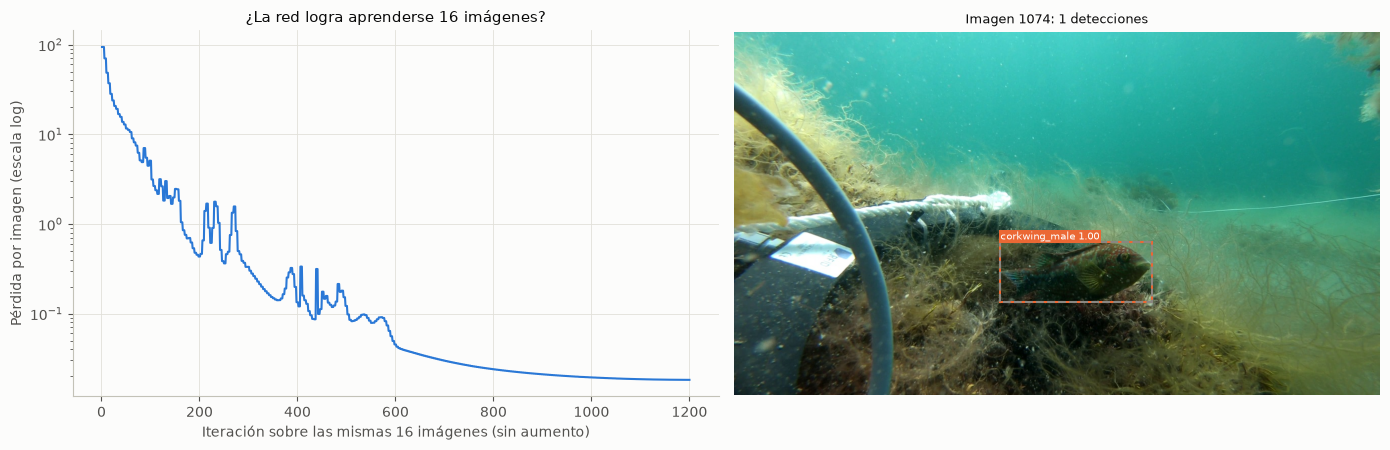

In [25]:
id_ejemplo = ids_sobreajuste[0]
img_ejemplo = Image.open(DIR_DATASET_ORIGINAL / "images" / "train" / f"{id_ejemplo}.jpg")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
axes[0].plot(curva_guardada.index + 1, curva_guardada.perdida, color=AZUL, lw=1.5)
axes[0].set_yscale("log")
axes[0].set_xlabel(f"Iteración sobre las mismas {IMAGENES_SOBREAJUSTE} imágenes (sin aumento)")
axes[0].set_ylabel("Pérdida por imagen (escala log)")
axes[0].set_title(f"¿La red logra aprenderse {IMAGENES_SOBREAJUSTE} imágenes?")
pred_ejemplo = pred_sobreajuste[(pred_sobreajuste.id == id_ejemplo) & (pred_sobreajuste.confianza >= UMBRAL_CONFIANZA)]
dibujar_cajas(axes[1], img_ejemplo, pred_ejemplo, f"Imagen {id_ejemplo}: {len(pred_ejemplo)} detecciones")
for fila in reales_sobreajuste[reales_sobreajuste.id == id_ejemplo].itertuples():
    axes[1].add_patch(plt.Rectangle((fila.x1, fila.y1), fila.x2 - fila.x1, fila.y2 - fila.y1, fill=False, ec=GRIS, lw=1.5, ls="--"))
fig.tight_layout()
fig.savefig(DIR_RESULTADOS / "prueba_sobreajuste.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Prueba de la escala de la pérdida

La pérdida de YOLOv3 es una suma por imagen, y su tamaño cambia cuánto se mueven los pesos con la tasa de 0,01 de `02`. Esta prueba la multiplica por cada factor de `ESCALAS_PROBADAS`, en entrenamientos de `EPOCAS_PRUEBA_ESCALA` épocas sobre todo train, midiendo en validación. La tasa cae como en el entrenamiento completo. Test no se usa. Con la GPU libre tarda unos 30 minutos; con `PROBAR_ESCALA = False` se muestra la prueba guardada.

La tabla muestra los valores de la última época y la fracción de actualizaciones recortadas, promediada en todas las épocas.

> **En esta variante** la prueba no se repite: se muestra la guardada del cuaderno original (`../02b_yolo_a_mano.ipynb`), hecha con la partición original. `PROBAR_ESCALA` debe quedar en `False`.

In [26]:
reales_val = cargar_cajas_reales(DIR_DATASET, "val", particion["val"])
# Esta variante no repite la prueba: muestra la guardada del cuaderno original
assert not PROBAR_ESCALA, "En esta variante la prueba no se repite: se muestra la del cuaderno original"
ARCHIVO_ESCALA = DIR_PRUEBA_GUARDADA / "prueba_escala_perdida.csv"


def probar_escala(ganancia):
    """Entrena unas pocas épocas con un factor de la pérdida; devuelve una fila por época."""
    random.seed(SEMILLA)
    torch.manual_seed(SEMILLA)
    datos = DatasetFjordFish("train", ids_train, aumentar=True)
    estado = Entrenamiento(YoloV3Tiny().to(DISPOSITIVO), math.ceil(len(datos) / LOTE), EPOCAS, ganancia)
    filas_escala = []
    for epoca in range(EPOCAS_PRUEBA_ESCALA):
        perdidas = entrenar_epoca(estado, datos, epoca)
        _, metricas_val, _ = validar(estado.ema.red, datos_val, reales_val)
        filas_escala.append({"escala": ganancia, "epoca": epoca + 1, "val_mAP50": metricas_val["mAP50"], "val_mAP50_95": metricas_val["mAP50_95"],
                             "perdida_train": perdidas["perdida"], "norma_gradiente": perdidas["norma_gradiente"],
                             "fraccion_recortada": perdidas["fraccion_recortada"]})
    return filas_escala


if PROBAR_ESCALA:
    modo_determinista(True)
    pd.DataFrame([fila for g in ESCALAS_PROBADAS for fila in probar_escala(g)]).to_csv(ARCHIVO_ESCALA, index=False)
    modo_determinista(False)
    torch.cuda.empty_cache()
assert ARCHIVO_ESCALA.exists(), "No hay una prueba guardada: usar PROBAR_ESCALA = True"
prueba_escala = pd.read_csv(ARCHIVO_ESCALA)
tabla_escala = prueba_escala[prueba_escala.epoca == prueba_escala.epoca.max()].set_index("escala")[["val_mAP50", "val_mAP50_95", "norma_gradiente"]]
tabla_escala["fraccion_recortada_media"] = prueba_escala.groupby("escala").fraccion_recortada.mean()
tabla_escala.round(3)

,val_mAP50,val_mAP50_95,norma_gradiente,fraccion_recortada_media
escala,,,,
1.0000,0.117,0.043,13.757,1.000
0.2500,0.116,0.040,5.786,0.018
0.0625,0.104,0.037,2.449,0.000


Izquierda: el mAP50-95 de validación por época para cada factor; la línea gris es la YOLOv8n de `02` en las mismas épocas, solo como referencia. Derecha: la fracción de actualizaciones en que actuó el recorte de gradiente.

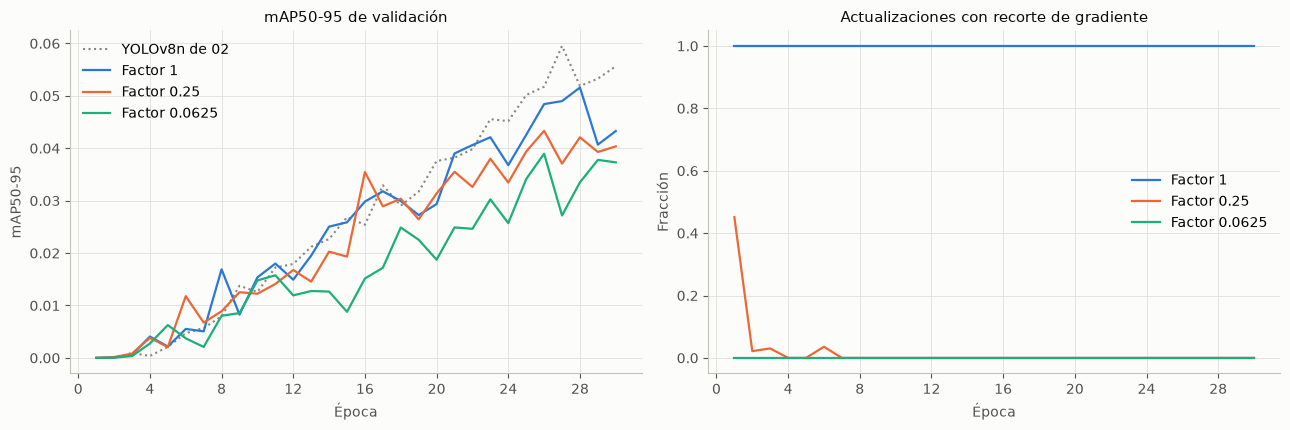

In [27]:
referencia = pd.read_csv(DIR_ORIGINAL / "resultados" / "yolo_desde_cero" / "historial.csv").query("epoca <= @EPOCAS_PRUEBA_ESCALA")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
axes[0].plot(referencia.epoca, referencia.val_mAP50_95, color=GRIS, lw=1.5, ls=":", label="YOLOv8n de 02")
for (ganancia, grupo), color in zip(prueba_escala.groupby("escala", sort=False), (AZUL, NARANJA, AQUA)):
    axes[0].plot(grupo.epoca, grupo.val_mAP50_95, color=color, lw=1.6, label=f"Factor {ganancia:g}")
    axes[1].plot(grupo.epoca, grupo.fraccion_recortada, color=color, lw=1.6, label=f"Factor {ganancia:g}")
axes[0].set_title("mAP50-95 de validación")
axes[0].set_ylabel("mAP50-95")
axes[1].set_title("Actualizaciones con recorte de gradiente")
axes[1].set_ylabel("Fracción")
for ax in axes:
    ax.set_xlabel("Época")
    ax.legend()
    epocas_enteras(ax)
fig.tight_layout()
fig.savefig(DIR_RESULTADOS / "prueba_escala_perdida.png", dpi=150, bbox_inches="tight")
plt.show()

**✍️ Decisión del grupo (D11):** factor de la pérdida = 0,25. Razón: ____.

## 12. Entrenamiento

Se entrena durante hasta `EPOCAS` épocas. Después de cada una se validan los pesos promediados (EMA), con el evaluador común, y se guardan si mejoran el mAP50-95 de validación; si no mejora en `PACIENCIA` épocas, el entrenamiento se detiene. El tiempo de cada época incluye la validación, y el entrenamiento corre en modo determinista, como YOLO. Test no se usa en esta sección.

En `~/tarea2_runs_80_10_10/reales/yolo_a_mano/` (fuera de OneDrive) quedan `mejor.pt`, `historial_completo.csv`, que se actualiza en cada época y permite seguir el avance, e `info_entrenamiento.json`.

Los pesos del mejor modelo y la configuración que se guarda junto a ellos, para saber con qué valores se entrenó.

In [28]:
PESOS = DIR_RUNS / "mejor.pt"
configuracion = {
    "lado": LADO, "strides": STRIDES, "anclas": ANCLAS_NP.tolist(), "umbral_ignorar": UMBRAL_IGNORAR,
    "pesos_perdida": [PESO_CAJA, PESO_OBJETO, PESO_FONDO, PESO_CLASE], "ganancia_perdida": GANANCIA_PERDIDA,
    "prob_objeto_inicial": PROB_OBJETO_INICIAL, "prob_clase_inicial": PROB_CLASE_INICIAL,
    "epocas": EPOCAS, "paciencia": PACIENCIA, "lote": LOTE, "lote_nominal": LOTE_NOMINAL,
    "tasa_inicial": TASA_INICIAL, "fraccion_tasa_final": FRACCION_TASA_FINAL, "momentum": MOMENTUM, "weight_decay": WEIGHT_DECAY,
    "epocas_calentamiento": EPOCAS_CALENTAMIENTO, "momentum_calentamiento": MOMENTUM_CALENTAMIENTO,
    "tasa_sesgos_calentamiento": TASA_SESGOS_CALENTAMIENTO, "norma_maxima_gradiente": NORMA_MAXIMA_GRADIENTE,
    "ema": [EMA_DECAIMIENTO, EMA_TAU], "precision_mixta": USAR_AMP,
}
aumento_datos = {"escala": ESCALA, "traslacion": TRASLACION, "hsv": [HSV_H, HSV_S, HSV_V], "volteo": VOLTEO, "mosaico": 0.0}

El ciclo de entrenamiento. `historial_completo.csv` se escribe en cada época, y `info_entrenamiento.json` solo si el entrenamiento termina.

In [29]:
if ENTRENAR:
    random.seed(SEMILLA)
    torch.manual_seed(SEMILLA)
    modelo = YoloV3Tiny().to(DISPOSITIVO)
    estado = Entrenamiento(modelo, math.ceil(len(datos_train) / LOTE), EPOCAS)
    PESOS.unlink(missing_ok=True)                 # así nunca se cargan los archivos de un entrenamiento anterior
    (DIR_RUNS / "info_entrenamiento.json").unlink(missing_ok=True)
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
    modo_determinista(True)                       # como YOLO (deterministic=True)
    filas_historial, mejor_valor, mejor_epoca, sin_mejora = [], -math.inf, 0, 0
    t_inicio = time.perf_counter()
    for epoca in range(1, EPOCAS + 1):
        perdidas_train = entrenar_epoca(estado, datos_train, epoca - 1)
        perdidas_val, metricas_val, _ = validar(estado.ema.red, datos_val, reales_val)
        filas_historial.append({
            "epoca": epoca, "tiempo_s": time.perf_counter() - t_inicio,
            "perdida_train": perdidas_train["perdida"], "perdida_val": perdidas_val["perdida"],
            "val_mAP50": metricas_val["mAP50"], "val_mAP50_95": metricas_val["mAP50_95"],
            **{f"perdida_{k}_train": perdidas_train[f"perdida_{k}"] for k in CLAVES_PERDIDA},
            **{f"perdida_{k}_val": perdidas_val[f"perdida_{k}"] for k in CLAVES_PERDIDA},
            "tasa": estado.optimizador.param_groups[1]["lr"], "norma_gradiente": perdidas_train["norma_gradiente"],
            "fraccion_recortada": perdidas_train["fraccion_recortada"],
            "cajas_sobrescritas": perdidas_train["sobrescritas"], "pasos_descartados": perdidas_train["pasos_descartados"]})
        pd.DataFrame(filas_historial).to_csv(DIR_RUNS / "historial_completo.csv", index=False)
        if metricas_val["mAP50_95"] > mejor_valor:
            mejor_valor, mejor_epoca, sin_mejora = metricas_val["mAP50_95"], epoca, 0
            torch.save(estado.ema.red.state_dict(), PESOS)
        else:
            sin_mejora += 1
        fila = filas_historial[-1]
        print(f"época {epoca:3d} | pérdida train {fila['perdida_train']:.3f} · val {fila['perdida_val']:.3f} | "
              f"val mAP50 {fila['val_mAP50']:.3f} · mAP50-95 {fila['val_mAP50_95']:.3f} | "
              f"gradiente {fila['norma_gradiente']:.1f} | {fila['tiempo_s'] / 60:5.1f} min")
        if epoca == 1:
            print(f"  ≈ {fila['tiempo_s'] / 60:.1f} min por época → {EPOCAS} épocas ≈ {fila['tiempo_s'] * EPOCAS / 3600:.1f} h como máximo")
        if sin_mejora >= PACIENCIA:
            print(f"Parada temprana: {PACIENCIA} épocas sin mejorar el mAP50-95 de validación (mejor época: {mejor_epoca})")
            break
        if not math.isfinite(perdidas_val["perdida"]):
            print(f"Se detiene en la época {epoca}: la pérdida de validación no es finita")
            break
    modo_determinista(False)
    assert mejor_epoca >= 1, "Ninguna época mejoró el criterio de parada (¿pérdida NaN?): no hay pesos que cargar"
    info_entrenamiento = {
        "modelo": "YOLOv3-tiny a mano", "tiempo_entrenamiento_s": round(time.perf_counter() - t_inicio, 1),
        "memoria_gpu_max_GB": round(torch.cuda.max_memory_reserved() / 1e9, 2) if torch.cuda.is_available() else None,
        "dispositivo": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
        "mejor_epoca": mejor_epoca, "configuracion": configuracion, "aumento_datos": aumento_datos,
        "fraccion_train": FRACCION_TRAIN, "semilla": SEMILLA, "huella_particion": huella,
    }
    (DIR_RUNS / "info_entrenamiento.json").write_text(json.dumps(info_entrenamiento, indent=2), encoding="utf-8")

época   1 | pérdida train 31.855 · val 25.560 | val mAP50 0.000 · mAP50-95 0.000 | gradiente 10.1 |   0.4 min
  ≈ 0.4 min por época → 300 épocas ≈ 1.9 h como máximo


época   2 | pérdida train 24.161 · val 22.915 | val mAP50 0.001 · mAP50-95 0.000 | gradiente 5.9 |   0.8 min


época   3 | pérdida train 22.770 · val 21.507 | val mAP50 0.003 · mAP50-95 0.001 | gradiente 6.2 |   1.2 min


época   4 | pérdida train 21.132 · val 21.360 | val mAP50 0.015 · mAP50-95 0.007 | gradiente 6.1 |   1.6 min


época   5 | pérdida train 19.681 · val 19.215 | val mAP50 0.017 · mAP50-95 0.004 | gradiente 5.7 |   2.0 min


época   6 | pérdida train 18.606 · val 18.178 | val mAP50 0.032 · mAP50-95 0.011 | gradiente 5.6 |   2.4 min


... (225 outputs left out)

época 232 | pérdida train 2.478 · val 10.254 | val mAP50 0.302 · mAP50-95 0.136 | gradiente 5.0 |  89.7 min


época 233 | pérdida train 2.406 · val 10.247 | val mAP50 0.298 · mAP50-95 0.130 | gradiente 4.9 |  90.1 min


época 234 | pérdida train 2.370 · val 10.319 | val mAP50 0.299 · mAP50-95 0.134 | gradiente 4.8 |  90.5 min


época 235 | pérdida train 2.321 · val 10.257 | val mAP50 0.294 · mAP50-95 0.130 | gradiente 5.0 |  90.9 min
Parada temprana: 50 épocas sin mejorar el mAP50-95 de validación (mejor época: 185)


Se carga la mejor época, con sus pesos promediados, que es la que se evalúa desde aquí en adelante. Con `ENTRENAR = False` se leen el historial y la información guardados, y se comprueba que las anclas calculadas son las del entrenamiento.

In [30]:
historial = pd.read_csv(DIR_RUNS / "historial_completo.csv")
info_entrenamiento = json.loads((DIR_RUNS / "info_entrenamiento.json").read_text(encoding="utf-8"))
assert np.allclose(info_entrenamiento["configuracion"]["anclas"], ANCLAS_NP), "Las anclas no son las del entrenamiento guardado"
modelo = YoloV3Tiny().to(DISPOSITIVO)
modelo.load_state_dict(torch.load(PESOS, map_location=DISPOSITIVO))
modelo.eval()
mejor_epoca = info_entrenamiento["mejor_epoca"]
tiempo_por_epoca_s = float(historial.tiempo_s.iloc[-1] / len(historial))
print(f"Tiempo total de entrenamiento: {info_entrenamiento['tiempo_entrenamiento_s'] / 60:.1f} min | "
      f"épocas: {len(historial)} | mejor época: {mejor_epoca} | tiempo medio por época: {tiempo_por_epoca_s:.1f} s")

Tiempo total de entrenamiento: 90.9 min | épocas: 235 | mejor época: 185 | tiempo medio por época: 23.2 s


## 13. Curvas de entrenamiento

Pérdidas de entrenamiento y validación por época e imagen (total y por término), mAP de validación, tasa de aprendizaje y norma del gradiente antes del recorte. La línea discontinua marca la mejor época.

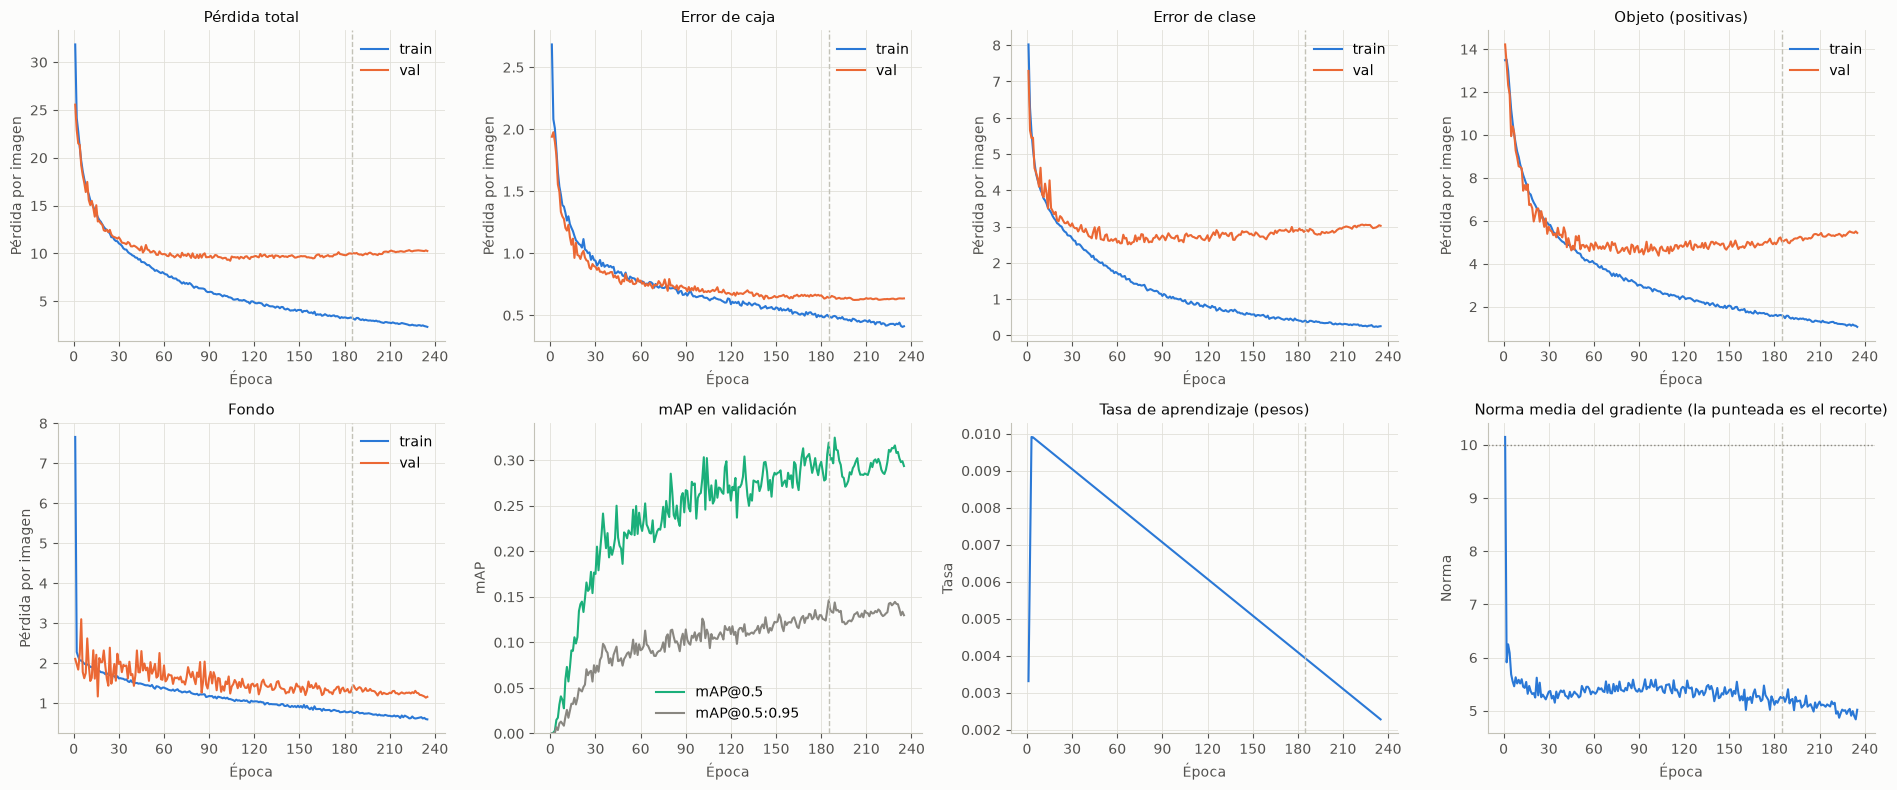

In [31]:
fig, axes = plt.subplots(2, 4, figsize=(19, 8))
axes = axes.ravel()
paneles = [("perdida", "Pérdida total"), ("perdida_caja", "Error de caja"), ("perdida_clase", "Error de clase"),
           ("perdida_objeto", "Objeto (positivas)"), ("perdida_fondo", "Fondo")]
for ax, (base, titulo) in zip(axes, paneles):
    ax.plot(historial.epoca, historial[f"{base}_train"], color=AZUL, lw=1.5, label="train")
    ax.plot(historial.epoca, historial[f"{base}_val"], color=NARANJA, lw=1.5, label="val")
    ax.set_title(titulo)
    ax.set_ylabel("Pérdida por imagen")
    ax.legend()
axes[5].plot(historial.epoca, historial.val_mAP50, color=AQUA, lw=1.5, label="mAP@0.5")
axes[5].plot(historial.epoca, historial.val_mAP50_95, color=GRIS, lw=1.5, label="mAP@0.5:0.95")
axes[5].set_title("mAP en validación")
axes[5].set_ylabel("mAP")
axes[5].set_ylim(0, None)
axes[5].legend()
axes[6].plot(historial.epoca, historial.tasa, color=AZUL, lw=1.5)
axes[6].set_title("Tasa de aprendizaje (pesos)")
axes[6].set_ylabel("Tasa")
axes[7].plot(historial.epoca, historial.norma_gradiente, color=AZUL, lw=1.5)
axes[7].axhline(NORMA_MAXIMA_GRADIENTE, color=GRIS, ls=":", lw=1)
axes[7].set_title("Norma media del gradiente (la punteada es el recorte)")
axes[7].set_ylabel("Norma")
for ax in axes:
    ax.set_xlabel("Época")
    ax.axvline(mejor_epoca, color="#c3c2b7", ls="--", lw=1)
    epocas_enteras(ax)
fig.tight_layout()
fig.savefig(DIR_RESULTADOS / "curvas_entrenamiento.png", dpi=150, bbox_inches="tight")
plt.show()

## 14. Evaluación en validación y test (evaluador común)

Se evalúa la mejor época en validación y, una sola vez, en test, en float32 y con el evaluador común de `comun.py`, el mismo de todos los modelos:
- **mAP50, mAP75 y mAP50-95** (definición COCO), promediando las clases con instancias en el conjunto evaluado;
- **precisión, recall y F1** con IoU 0,5 y confianza ≥ `UMBRAL_CONFIANZA`, promediados entre clases (umbral común del grupo, D8).

In [32]:
CLAVES_METRICAS = ("precision", "recall", "F1", "mAP50", "mAP75", "mAP50_95")
predicciones, metricas = {}, {}
for split, dataset in (("val", datos_val), ("test", datos_test)):
    predicciones[split] = predecir(modelo, dataset)
    reales = cargar_cajas_reales(DIR_DATASET, split, particion[split])
    metricas[split] = evaluar_detecciones(predicciones[split], reales, nombres=NOMBRES, umbral_confianza=UMBRAL_CONFIANZA)
    print(f"{split}: {len(predicciones[split])} detecciones en {predicciones[split].id.nunique()} imágenes")

tabla_global = pd.DataFrame({s: {k: m[k] for k in CLAVES_METRICAS} for s, m in metricas.items()}).T.rename_axis("partición")
tabla_global.to_csv(DIR_RESULTADOS / "metricas_val_test.csv")
tabla_global.round(4)

val: 12650 detecciones en 301 imágenes


test: 13769 detecciones en 301 imágenes


,precision,recall,F1,mAP50,mAP75,mAP50_95
partición,,,,,,
val,0.3021,0.3364,0.3183,0.3187,0.1004,0.1461
test,0.3256,0.3345,0.3300,0.3554,0.1041,0.1422


AP por clase en test (solo aparecen las clases con instancias en test).

In [33]:
por_clase = metricas["test"]["por_clase"]
por_clase.to_csv(DIR_RESULTADOS / "metricas_por_clase_test.csv", index=False)
por_clase.sort_values("instancias", ascending=False).reset_index(drop=True).round(4)

,clase_id,clase,instancias,predicciones,AP50,AP75,AP50_95
0,5,goldsinny,159,4020,0.4258,0.1248,0.1907
1,4,corkwing_male,117,1574,0.7804,0.2755,0.3456
2,8,cod,87,1236,0.7195,0.3486,0.3681
3,16,spiny_dogfish,51,728,0.6645,0.2334,0.3052
4,3,corkwing_female,51,866,0.5625,0.1313,0.2398
5,15,gadines_unknown,36,617,0.3420,0.0565,0.1158
6,7,labrids_unknown,34,794,0.1452,0.0016,0.0372
7,18,brown_crab,18,541,0.1137,0.0598,0.0538
8,9,cod_yoy,14,403,0.3550,0.0627,0.1239
9,11,pollack,13,621,0.1946,0.1052,0.0898


El mismo AP50 por clase como gráfico, de menor a mayor, con el número de instancias de cada clase en test.

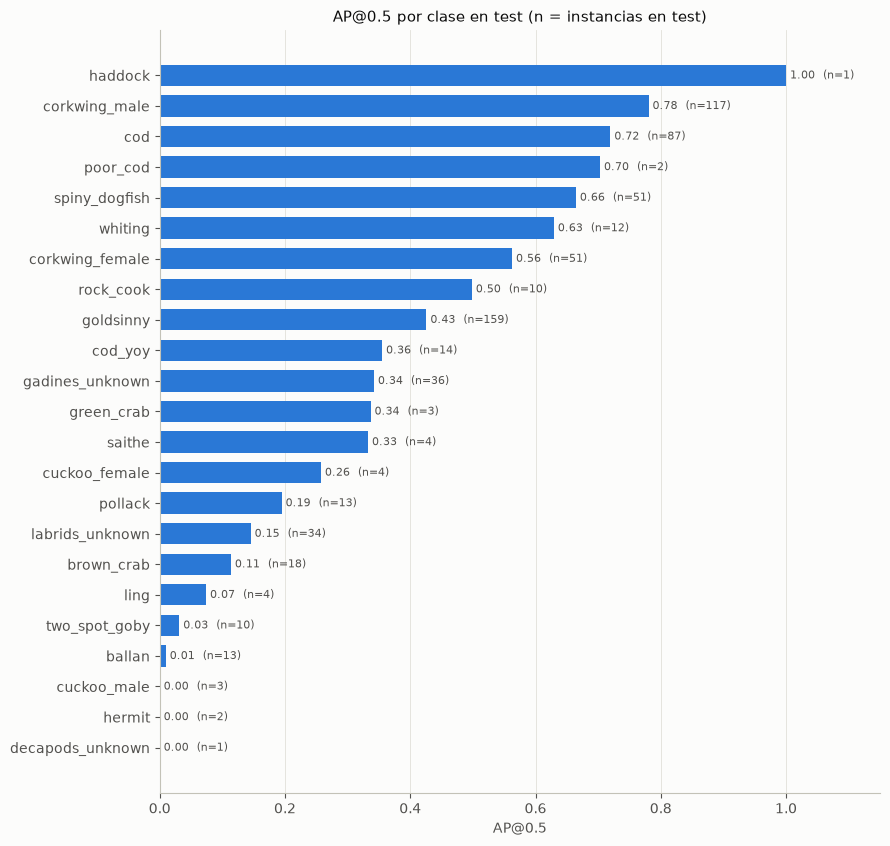

In [34]:
barras = por_clase.sort_values(["AP50", "instancias"])
fig, ax = plt.subplots(figsize=(9, 0.32 * len(barras) + 1.2))
ax.barh(barras.clase, barras.AP50, height=0.7, color=AZUL)
for yi, (v, n) in enumerate(zip(barras.AP50, barras.instancias)):
    ax.text(v, yi, f" {v:.2f}  (n={n})", va="center", fontsize=8, color="#52514e")
ax.set_xlim(0, 1.15)
ax.set_xlabel("AP@0.5")
ax.set_title("AP@0.5 por clase en test (n = instancias en test)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(DIR_RESULTADOS / "ap50_por_clase_test.png", dpi=150, bbox_inches="tight")
plt.show()

Curva precisión-recall en test con IoU 0,5: la precisión media entre clases para cada nivel de recall. El área bajo la curva es el mAP50.

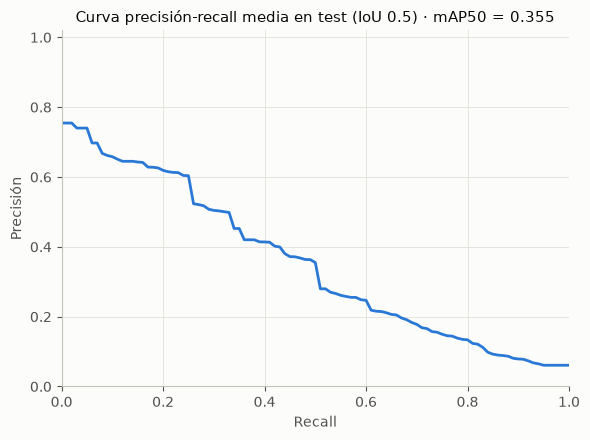

In [35]:
curva = metricas["test"]["curva_pr"]
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(curva.recall, curva.precision, color=AZUL, lw=2)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_xlabel("Recall")
ax.set_ylabel("Precisión")
ax.set_title(f"Curva precisión-recall media en test (IoU 0.5) · mAP50 = {metricas['test']['mAP50']:.3f}")
fig.tight_layout()
fig.savefig(DIR_RESULTADOS / "curva_pr_test.png", dpi=150, bbox_inches="tight")
plt.show()

## 15. Eficiencia: tamaño del modelo y velocidad de inferencia

Se miden los parámetros, los GFLOPs a 640 × 640, el tamaño del archivo de pesos y la velocidad con **lote de 1 imagen** sobre imágenes de test, después de un calentamiento. El tiempo se separa en preproceso (letterbox y paso a la GPU), inferencia y postproceso (decodificación y NMS). Son las mismas mediciones de los demás cuadernos, en float32, con el lienzo de 640 × 640 y solo con las detecciones de confianza ≥ `UMBRAL_CONFIANZA`.

In [36]:
def sincronizar():
    """Espera a que la GPU termine, para medir tiempos reales."""
    if DISPOSITIVO.type == "cuda":
        torch.cuda.synchronize()


@torch.no_grad()
def medir_tiempos(ruta):
    """Milisegundos de preproceso, inferencia y postproceso de una imagen con lote 1 (ya leída de disco), en float32."""
    original = cv2.imread(str(ruta))
    sincronizar()
    t0 = time.perf_counter()
    lienzo, *_ = ubicar_en_lienzo(redimensionar(original), np.zeros((0, 4)))
    imagen = torch.from_numpy(np.ascontiguousarray(lienzo[..., ::-1].transpose(2, 0, 1)))[None]
    imagen = imagen.to(DISPOSITIVO).float() / 255
    sincronizar()
    t1 = time.perf_counter()
    salida = modelo(imagen)
    sincronizar()
    t2 = time.perf_counter()
    postprocesar(salida, conf_minima=UMBRAL_CONFIANZA)
    sincronizar()
    t3 = time.perf_counter()
    return {"preprocess": (t1 - t0) * 1000, "inference": (t2 - t1) * 1000, "postprocess": (t3 - t2) * 1000}

Se miden `N_IMAGENES_VELOCIDAD` imágenes de test con lote 1 y, aparte, el tiempo de inferencia por imagen con lotes de `LOTE_EVALUACION` imágenes (`ms_inferencia_en_lote`). Para este último se usan imágenes al azar, porque el tiempo de la red no depende del contenido de la imagen.

In [37]:
for ruta in rutas_test[:10]:                     # calentamiento
    medir_tiempos(ruta)
tiempos = pd.DataFrame([medir_tiempos(ruta) for ruta in rutas_test[:N_IMAGENES_VELOCIDAD]])
ms_total = float(tiempos.sum(axis=1).mean())

lote_prueba = torch.rand(LOTE_EVALUACION, 3, LADO, LADO, device=DISPOSITIVO)
with torch.no_grad():                            # float32, como la evaluación de YOLO
    for _ in range(3):                           # calentamiento
        modelo(lote_prueba)
    sincronizar()
    t_inicio = time.perf_counter()
    for _ in range(10):
        modelo(lote_prueba)
    sincronizar()
ms_inferencia_en_lote = (time.perf_counter() - t_inicio) * 1000 / (10 * LOTE_EVALUACION)

n_parametros, gflops = tamano_de_la_red(modelo)   # del modelo entrenado
eficiencia = {
    "parametros_M": n_parametros / 1e6,
    "GFLOPs": gflops,
    "tamano_pesos_MB": PESOS.stat().st_size / 1e6,
    "ms_preproceso": float(tiempos.preprocess.mean()),
    "ms_inferencia": float(tiempos.inference.mean()),
    "ms_postproceso": float(tiempos.postprocess.mean()),
    "ms_total_por_imagen": ms_total,
    "FPS": 1000 / ms_total,
    "ms_inferencia_en_lote": ms_inferencia_en_lote,
}
pd.Series(eficiencia).round(3).to_frame("valor")

,valor
parametros_M,8.732
GFLOPs,12.980
tamano_pesos_MB,34.974
ms_preproceso,3.667
ms_inferencia,6.185
ms_postproceso,3.179
ms_total_por_imagen,13.031
FPS,76.737
ms_inferencia_en_lote,2.911


## 16. Resultados cualitativos

Las mismas imágenes de test que muestran los demás cuadernos (misma semilla): anotación real a la izquierda y predicción a la derecha (confianza ≥ `UMBRAL_CONFIANZA`).

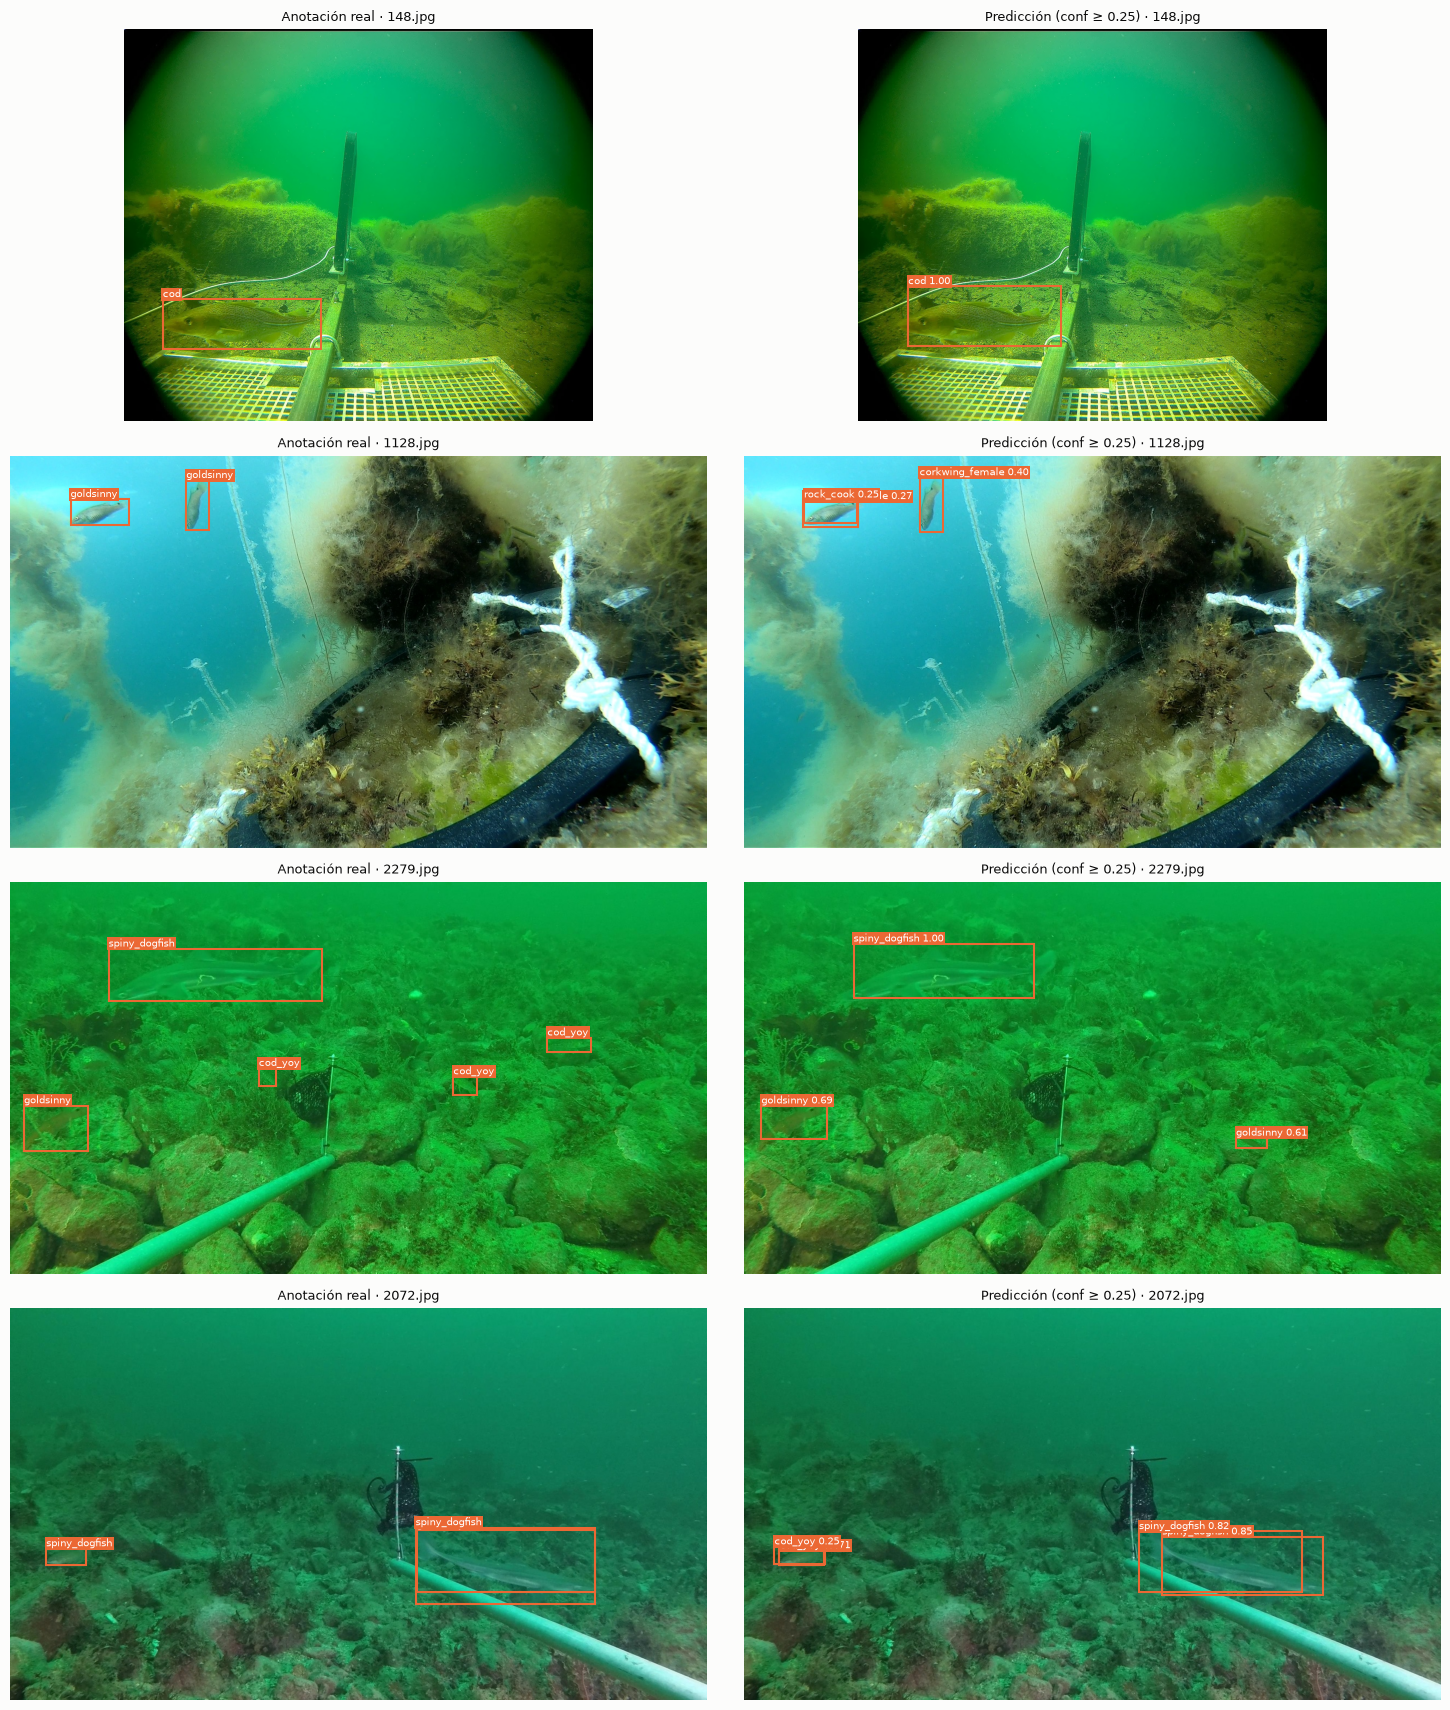

In [38]:
ejemplos = random.Random(SEMILLA).sample(rutas_test, N_EJEMPLOS)
reales_test = cargar_cajas_reales(DIR_DATASET, "test", particion["test"])
pred_test = predicciones["test"]
fig, axes = plt.subplots(N_EJEMPLOS, 2, figsize=(15, 4.3 * N_EJEMPLOS))
for (ax_real, ax_pred), ruta in zip(axes, ejemplos):
    img = Image.open(ruta)
    dibujar_cajas(ax_real, img, reales_test[reales_test.id == ruta.stem], f"Anotación real · {ruta.name}")
    dibujar_cajas(ax_pred, img, pred_test[(pred_test.id == ruta.stem) & (pred_test.confianza >= UMBRAL_CONFIANZA)],
                  f"Predicción (conf ≥ {UMBRAL_CONFIANZA}) · {ruta.name}")
fig.tight_layout()
fig.savefig(DIR_RESULTADOS / "ejemplos_test.png", dpi=120, bbox_inches="tight")
plt.show()

## 17. Predicciones y resumen para la comparación

Se guardan en `resultados/yolo_a_mano/`, con el mismo formato de los demás modelos: `predicciones_val.csv` y `predicciones_test.csv`, `historial.csv` (columnas comunes por época) y `resumen.json` / `resumen.csv`, con las mismas claves. `05_comparacion.ipynb` recalcula las métricas de todos los modelos con el umbral común (D8).

In [39]:
for split in ("val", "test"):
    predicciones[split].to_csv(DIR_RESULTADOS / f"predicciones_{split}.csv", index=False)
COLUMNAS_HISTORIAL = ["epoca", "tiempo_s", "perdida_train", "perdida_val", "val_mAP50", "val_mAP50_95"]
historial[COLUMNAS_HISTORIAL].to_csv(DIR_RESULTADOS / "historial.csv", index=False)

resumen = {
    "modelo": "YOLOv3-tiny a mano",
    "huella_particion": huella,
    "epocas_ejecutadas": int(historial.epoca.max()),
    "mejor_epoca": mejor_epoca,
    "tiempo_entrenamiento_min": info_entrenamiento["tiempo_entrenamiento_s"] / 60,
    "tiempo_por_epoca_s": tiempo_por_epoca_s,
    "memoria_gpu_max_GB": info_entrenamiento["memoria_gpu_max_GB"],
    **{f"test_{k}": metricas["test"][k] for k in CLAVES_METRICAS},
    **{f"val_{k}": metricas["val"][k] for k in CLAVES_METRICAS},
    **eficiencia,
}
(DIR_RESULTADOS / "resumen.json").write_text(json.dumps(resumen, indent=2, ensure_ascii=False), encoding="utf-8")
pd.Series(resumen).to_frame("valor").to_csv(DIR_RESULTADOS / "resumen.csv")
pd.Series(resumen).to_frame("valor")

,valor
modelo,YOLOv3-tiny a mano
huella_particion,84ea7ae5b688
epocas_ejecutadas,235
mejor_epoca,185
tiempo_entrenamiento_min,90.893333
tiempo_por_epoca_s,23.206831
memoria_gpu_max_GB,2.75
test_precision,0.325561
test_recall,0.334529
test_F1,0.329984


## 18. ✍️ Justificación de las decisiones (completar por el grupo)

> La tarea pide justificar estas decisiones con argumentos propios del grupo; el uso de IA generativa para diseñar la solución o analizar resultados está prohibido.

- **Arquitectura** (YOLOv3-tiny, escalas, filtros):
- **Anclas** (cantidad y cálculo con k-means):
- **Asignación y función de pérdida**:
- **Escala de la pérdida** (`GANANCIA_PERDIDA`, resultado de la sección 11):
- **Resolución de entrada y letterbox**:
- **Optimizador, tasa de aprendizaje y tamaño de lote**:
- **Calentamiento, acumulación, EMA y recorte de gradiente**:
- **Número de épocas y parada temprana**:
- **Regularización** (weight decay, aumento de datos, parada temprana):
- **Aumento de datos**:

## 19. ✍️ Análisis de resultados (completar por el grupo)

-

## ✍️ Declaración de uso de IA generativa

> Completar según lo que pide la tarea (herramienta y propósito específico).